## Assignment 2: Fine-tune a Language Model for Downstream Tasks

> CISC7021 Applied Natural Language Processing (2024/2025)

In this assignment, we will use a toy **Llama-2** language model (the same model used in Assignment 1) to conduct a sentiment analysis task using **zero-shot prompting** and **fine-tuning**, and subsequently evaluate its performance.

We will learn how to prompt the language model for sentiment classification, evaluate its task-specific performance, and perform fine-tuning using the PyTorch and Hugging Face libraries. Detailed instructions are provided in the attached notebook.

---

🚨 **How to make Full Use of Colab/Kaggle GPU Quotas?**
1. Begin by debugging your code on the CPU to ensure there are no errors, and then run it on the GPU to make full use of the available free GPU quotas.
2. In this assignment, the **inference/evaluation tasks on CPU (Task 1 & 2)** are pretty fast!
3. To clear the GPU cache, try using **torch.cuda.empty_cache()**. If you continue to run out of memory, consider restarting your environment.

🚨 Please note that training on CPU may be slow. If running on Google Colab or Kaggle, you can avoid this by going to **Runtime > Change runtime type > Hardware accelerator > GPU > GPU type > T4**. This should be included within the free tier of Colab.

---

We start by doing a `pip install` of all required libraries.
- 🤗 `transformers`, `datasets`, `accelerate` are Huggingface libraries.
- By default, Colab has `transformers`, `pytorch` libraries installed. If you are using a local machine, please install them via `pip` or `conda`.

In [1]:
#!pip install torch torchvision torchaudio
#!pip install transformers

In [2]:
!pip install datasets accelerate -q


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### (Optional) Uploading the model/data to Google Colab or Kaggle.

⚠️ In this assignment, we will utilize online model checkpoints and datasets for improved accessibility. They will facilitate seamless transitions between different environments.

However, if you prefer to work with Google Drive or another platform, you are welcome to replace the online path with the path corresponding to your chosen environment.

For Colab users, you can mount your Google Drive files by running the following code snippet:

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')

### Necessary Packages, Environment Setups

In [1]:
from itertools import chain

import numpy as np
import torch
from datasets import load_dataset
from tqdm.notebook import tqdm
from transformers import (
    AutoTokenizer,
    LlamaForCausalLM,
    LlamaForSequenceClassification,
    LlamaTokenizer,
    Trainer,
    TrainingArguments,
)

### Added: run configuration

Directory setup, random seeds and the artifact/checkpoint locations used by the added cells.

In [2]:
# ===== Added: local run configuration (directories / reproducibility / speed) =====
import os, json, time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# --- Locate the project root independently of the working directory ----------
# Layout: <PROJECT_ROOT>/notebook/<this notebook>, with the generated products in
# <PROJECT_ROOT>/{results,artifacts,figures,checkpoints}.  The kernel can be started from
# any folder (VS Code opens it in the notebook folder, a terminal or a batch runner
# somewhere else), so the root is taken from the first anchor that really points at the
# project instead of trusting os.getcwd() blindly:
#   1. CISC7021_PROJECT_ROOT environment variable (explicit override)
#   2. __vsc_ipynb_file__: the path of this notebook, injected by the VS Code Jupyter
#      extension -> the project root is the parent of the notebook folder
#   3. the current working directory, walking upwards until the project is recognised
_ROOT_FOLDERS = ("results", "artifacts", "figures", "checkpoints")


def _looks_like_project_root(path):
    """True if *path* contains this project: its notebook folder or two product folders."""
    if not path or not os.path.isdir(path):
        return False
    if os.path.isdir(os.path.join(path, "notebook")):
        return True
    return sum(os.path.isdir(os.path.join(path, _f)) for _f in _ROOT_FOLDERS) >= 2


def _resolve_project_root():
    override = os.environ.get("CISC7021_PROJECT_ROOT")
    if override:
        return os.path.abspath(override), "CISC7021_PROJECT_ROOT"
    notebook_file = globals().get("__vsc_ipynb_file__")
    if notebook_file:
        candidate = os.path.dirname(os.path.dirname(os.path.abspath(notebook_file)))
        if _looks_like_project_root(candidate):
            return candidate, "__vsc_ipynb_file__"
    candidate = os.path.abspath(os.getcwd())
    while True:
        if _looks_like_project_root(candidate):
            return candidate, "cwd"
        _parent = os.path.dirname(candidate)
        if _parent == candidate:
            break
        candidate = _parent
    return os.path.abspath(os.getcwd()), "cwd (fallback)"


LAUNCH_CWD = os.path.abspath(os.getcwd())
PROJECT_ROOT, PROJECT_ROOT_SOURCE = _resolve_project_root()

RESULTS_DIR = os.path.abspath(os.environ.get("CISC7021_RUN_DIR") or os.path.join(PROJECT_ROOT, "results"))
# large intermediate files (model checkpoints): kept outside the results folder on purpose
CHECKPOINT_ROOT = os.path.abspath(os.environ.get("CISC7021_CHECKPOINT_ROOT") or os.path.join(PROJECT_ROOT, "checkpoints"))
ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts")
FIGURE_DIR = os.path.join(PROJECT_ROOT, "figures")
for _d in (RESULTS_DIR, CHECKPOINT_ROOT, ARTIFACT_DIR, FIGURE_DIR):
    os.makedirs(_d, exist_ok=True)

# The original assignment cells save their ten result files under plain relative names, so
# the kernel is moved into the results folder: they then land in <PROJECT_ROOT>/results no
# matter where the notebook was started from.
os.chdir(RESULTS_DIR)
if PROJECT_ROOT_SOURCE == "cwd (fallback)":
    print("WARNING: project root could not be identified, falling back to the working directory.")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    # Ampere+ tf32 matmuls: measured 0.94 s/step -> 0.74 s/step for this tiny model.
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

EXTRA_RECORDS = []      # metric records of the added (optional) experiments

print("LAUNCH CWD        :", LAUNCH_CWD)
print("PROJECT_ROOT      :", PROJECT_ROOT, "[from:", PROJECT_ROOT_SOURCE + "]")
print("RESULTS_DIR       :", RESULTS_DIR)
print("CHECKPOINT_ROOT   :", CHECKPOINT_ROOT)
print("ARTIFACT_DIR      :", ARTIFACT_DIR)
print("FIGURE_DIR        :", FIGURE_DIR)


LAUNCH CWD        : C:\Users\07viv\Desktop\CISC7021_Ass2\notebook
PROJECT_ROOT      : C:\Users\07viv\Desktop\CISC7021_Ass2 [from: cwd]
RESULTS_DIR       : C:\Users\07viv\Desktop\CISC7021_Ass2\results
CHECKPOINT_ROOT   : C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints
ARTIFACT_DIR      : C:\Users\07viv\Desktop\CISC7021_Ass2\artifacts
FIGURE_DIR        : C:\Users\07viv\Desktop\CISC7021_Ass2\figures


Please set the correct file path based on your environment.

- If you are using Colab, the path may be: `/content/drive/MyDrive/xxxxxx`
- If you are using Kaggle, the path may be: `/kaggle/input/xxxxxx`

In [3]:
# In this assignment, we will utilize online model checkpoints and datasets for improved accessibility.
# If you prefer to work with Google Drive or another platform, you are welcome to replace the online path with the path corresponding to your chosen environment.
MODEL_FOLDER = "rzzhan/tiny-llama-stories-42m"
# MODEL_FOLDER = "/content/drive/MyDrive/assignment1/llama-42m"

Load the model checkpoint into either a GPU or CPU.

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

model_path = MODEL_FOLDER
# Load model from local files/online files
model = LlamaForCausalLM.from_pretrained(model_path).to(device)
# Load tokenizer from local files/online files
tokenizer = AutoTokenizer.from_pretrained(model_path, device=device)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Device type: cuda


### Task 1: Zero-shot Prompting for Sentiment Analysis

#### 💡Tutorials: How to Prompt the Language Model Using Our Prepared Function

We have developed the function `prompting_classification()` for conducting experiments on this task. To get started, you will need to prepare two hyper-parameters: the `batch size`, which should be suited to your environment, and the `prompts` for the model.

---
Minimal example:

```python
# Step 1: Load the Rotten Tomatoes dataset online
rto_data = load_dataset("cornell-movie-review-data/rotten_tomatoes")

# Step 2: Define a mapping for sentiment labels: 0 represents "bad" reviews, and 1 represents "good" reviews.
RTO_DATA_LABEL_MAPPING = {
    0: "bad",
    1: "good"
}

# Step 3: Define the prompt to be used for classification tasks.
rto_prompt = "Is this moive bad or good? This moive is "

# Call the prompting_classification function to classify movie reviews
prompting_classification(model=model,
                         tokenizer=tokenizer,
                         dataset=rto_data["validation"]["text"],
                         batch_size=32,
                         label_mapping=RTO_DATA_LABEL_MAPPING,
                         prompt=rto_prompt)

```

Important parameters:

- `dataset`: By default, we load a dataset from Huggingface hub. You can use the function defined in the previous Assignment for loading an external dataset.
- `batch_size`: The number of reviews to process in a single batch. This affects memory usage and processing speed during inference.
- `label_mapping`: A dictionary that maps numerical labels to their corresponding sentiment labels. For example, 0 maps to "bad" and 1 maps to "good".
- `prompt`: A string that serves as the prompt for the classification task. It provides context to the model about what is being asked (e.g., whether a movie is bad or good).

Returns:
- `y_pred`: e.g., `[1, 0, 1, ....]` A list containing the classification results.

---


---

By default, we have defined a function called `prompt_template` to generate prompts. However, you can also customize the prompt according to your own preferences.

```python
# Generate a prompt suffix for classification tasks based on the provided label names and text type.
prompt_template(["bad", "good"], "movie")
    -> will return "Is this moive bad or good? This moive is "
```


Important Parameters:
- `label_names` (list of str): A list of possible label names for the classification task.
- `text_type` (str): A string indicating the type of text being classified (e.g., "movie", "review").


Returns:
- `prompt_suffix`: A prompt suffix that asks whether the given text belongs to one of the specified labels.


---


⚠️ Please make sure to **run the following cell first** to define the functions.

😊 **You do not need to check the details of `predict_prob(), prompting_classification()` function!** However, if you are interested, you can refer to the following illustration figure.


Illustrations:

![illustration](https://huggingface.co/blog/assets/106_zero_shot_eval_on_the_hub/zeroshot.jpg)


In [5]:
@torch.inference_mode()
def predict_prob(model, num_labels, input_ids, label_name_ids, attention_mask=None):
    """Label log-probabilities read at the position that ends each prompt.

    ``input_ids`` is a padded batch (``prompting_classification`` tokenises with
    ``padding=True`` and the tokenizer pads on the **right**), so ``logits[:, -1, :]``
    is only correct for the longest sequence of the batch: for every shorter sample
    that column is a padding placeholder, and the class scores were read there.

    With ``attention_mask`` supplied, the scores of each sample are therefore taken at
    its own last *real* token: the largest column index whose mask is still 1. The
    label words are still scored by summing the log-probabilities of their sub-token
    ids at that position (multi-token labels keep working). Called without
    ``attention_mask`` the old fixed-column behaviour is kept for backward
    compatibility, and a warning is printed.
    """
    if attention_mask is None:
        print(
            "[predict_prob] WARNING: no attention_mask passed - falling back to the legacy "
            "behaviour that reads logits[:, -1, :]; with a right-padded batch that column is a "
            "padding placeholder for every sample shorter than the longest one."
        )
        logits = model(input_ids).logits
        last_positions = torch.full(
            (logits.shape[0],), logits.shape[1] - 1, dtype=torch.long, device=logits.device
        )
    else:
        logits = model(input_ids, attention_mask=attention_mask).logits
        positions = torch.arange(logits.shape[1], device=logits.device).unsqueeze(0)
        # last column whose attention mask is still 1 == end of the real prompt
        last_positions = (positions * attention_mask.to(logits.device)).max(dim=1).values

    rows = torch.arange(logits.shape[0], device=logits.device)
    logits = logits[rows, last_positions, :]          # one row per sample, never a pad column
    log_probabilities = torch.nn.functional.log_softmax(logits, dim=-1)
    class_log_prob = torch.zeros(
        (log_probabilities.shape[0], num_labels), device=log_probabilities.device
    )
    for i, label_token_ids in enumerate(label_name_ids):
        total_log_prob = torch.sum(log_probabilities[:, label_token_ids], axis=-1)
        class_log_prob[:, i] = total_log_prob
    return class_log_prob


def prompting_classification(model, tokenizer, dataset, batch_size, label_mapping, prompt):
    label_names = [label_mapping[i] for i in range(len(label_mapping))]
    num_labels = len(label_names)

    label_name_ids = [
        tokenizer.encode(label, add_special_tokens=False) for label in label_names
    ]

    y_pred = []
    for i in tqdm(range(0, len(dataset), batch_size)):
        batch_input = dataset[i : i + batch_size]
        batch_input = [i + " " + prompt for i in batch_input]
        tokenized_input = tokenizer(batch_input, return_tensors="pt", padding=True).to(
            device
        )
        class_log_prob = (
            predict_prob(
                model,
                num_labels,
                tokenized_input["input_ids"],
                label_name_ids,
                attention_mask=tokenized_input["attention_mask"],
            ).detach().cpu()
        )
        preds = torch.argmax(class_log_prob, axis=1).flatten().tolist()
        y_pred += preds
    return y_pred


Dataset settings

In [6]:
# DO NOT CHANGE DATSET SOURCES! #
rto_data = load_dataset("cornell-movie-review-data/rotten_tomatoes")
sst5_data = load_dataset("SetFit/sst5")
# DO NOT CHANGE DATSET SOURCES! #

# If you wish to customize the label mapping rules, please ensure that you use synonyms.
# Avoid using terms that have opposite meanings!
RTO_DATA_LABEL_MAPPING = {0: "bad", 1: "good"}
SST5_DATA_LABEL_MAPPING = {
    0: "awful",
    1: "bad",
    2: "average",
    3: "good",
    4: "excellent",
}

Repo card metadata block was not found. Setting CardData to empty.


In [10]:
print(rto_data["train"][0])

{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'label': 1}


In [11]:
print(sst5_data["train"][0])

{'text': 'a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films', 'label': 4, 'label_text': 'very positive'}


#### Task 1 Playground

---

📚 Task 1: Zero-shot Prompting for Sentiment Analysis
1. (Required) Perform zero-shot prompting for sentiment analysis on **Rotten Tomatoes** and **SST-5** dataset (dev&test).
2. (Optional) You are encouraged to change the prompts and discuss your findings.

---

In [7]:
# ⬇️ try your prompt template
def prompt_template(label_names, text_type):
    # If there are exactly two labels, join them with " or ".
    if len(label_names) == 2:
        label_name_str = " or ".join(label_names)
    else:
        # For more than two labels, join them with commas and an "or" before the last label.
        label_name_str = ", ".join(label_names[:-1]) + ", or " + label_names[-1]

    # Create the final prompt suffix.
    prompt_suffix = f"Is this {text_type} {label_name_str}? This {text_type} is "

    return prompt_suffix

In [8]:
# Skeleton Code: Zero-shot Prompting on Rotten Tomatoes dataset.

eval_batch_size = 32

label_names = [RTO_DATA_LABEL_MAPPING[i] for i in range(len(RTO_DATA_LABEL_MAPPING))]
rto_prompt = prompt_template(label_names, "movie")  # ⬅️ try your prompt template
print(f"Used Prompt: {rto_prompt}")

# Dev split
rto_val_pred = prompting_classification(
    model=model,
    tokenizer=tokenizer,
    dataset=rto_data["validation"]["text"],
    batch_size=eval_batch_size,
    label_mapping=RTO_DATA_LABEL_MAPPING,
    prompt=rto_prompt,
)

# Test split
rto_test_pred = prompting_classification(
    model=model,
    tokenizer=tokenizer,
    dataset=rto_data["test"]["text"],
    batch_size=eval_batch_size,
    label_mapping=RTO_DATA_LABEL_MAPPING,
    prompt=rto_prompt,
)

Used Prompt: Is this movie bad or good? This movie is 


  0%|          | 0/34 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

In [9]:
# Skeleton Code: Zero-shot Prompting on SST-5 dataset.

eval_batch_size = 32

label_names = [SST5_DATA_LABEL_MAPPING[i] for i in range(len(SST5_DATA_LABEL_MAPPING))]
sst5_prompt = prompt_template(label_names, "text")  # ⬅️ try your prompt template
print(f"Used Prompt: {sst5_prompt}")

sst5_val_pred = prompting_classification(
    model=model,
    tokenizer=tokenizer,
    dataset=sst5_data["validation"]["text"],
    batch_size=eval_batch_size,
    label_mapping=SST5_DATA_LABEL_MAPPING,
    prompt=sst5_prompt,
)

sst5_test_pred = prompting_classification(
    model=model,
    tokenizer=tokenizer,
    dataset=sst5_data["test"]["text"],
    batch_size=eval_batch_size,
    label_mapping=SST5_DATA_LABEL_MAPPING,
    prompt=sst5_prompt,
)

Used Prompt: Is this text awful, bad, average, good, or excellent? This text is 


  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

#### Export the results for uploading. Please do not modifiy the output format!

In [10]:
def save_results(dataset, pred, output_file):
    predicted_texts = zip(dataset, pred)
    # Write the paired results to a text file
    with open(output_file, "w", encoding="utf-8", newline="\n") as f:
        for text, prediction in predicted_texts:
            f.write(f"{prediction} ||| {text}\n")

save_results(sst5_data["validation"]["text"], sst5_val_pred, "sst5-val-prompting.txt")
save_results(sst5_data["test"]["text"], sst5_test_pred, "sst5-test-prompting.txt")
save_results(rto_data["validation"]["text"], rto_val_pred, "rto-val-prompting.txt")
save_results(rto_data["test"]["text"], rto_test_pred, "rto-test-prompting.txt")

### Task 2: Accuracy and F1 Score Evaluation

#### 💡Hints: $F_1$ score, Macro-$F_1$

---

**$F_1$ Score**

The $F_1$ score is the harmonic mean of precision and recall, providing a balance between the two. The $F_1$ score is particularly useful when the class distribution is imbalanced.


- **Precision**: $ \text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}} $

- **Recall**: $ \text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}} $

- **$F_1$ Score**:

  $$
  F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
  $$


---
**Macro-$F_1$ Score**

The Macro-$F_1$ score is an extension of the $F_1$ score used in multiclass classification problems. It calculates the $F_1$ score for each class independently and then takes the average, treating all classes equally regardless of their size.


  $$
  \text{Macro-}F_1 = \frac{1}{N} \sum_{i=1}^{N} F_{1,i}
  $$

  where $N$ is the number of classes and $F_{1,i}$ is the $F_1$ score for class $i$.

The Macro-$F_1$ score is useful when you want to ensure that all classes are treated equally, even if they vary in size.

---

#### Task 2 Playground

---

📚 Task 2: Accuracy and F1 score evaluation.
1. (Required) Complete the remaining code in the `calculate_f1_score` function.
2. (Required) Report the classification performance for Task 1, including the development and test performance for the Rotten Tomatoes and SST-5 datasets.

---

In [11]:
def calculate_accuracy(y_true, y_pred):
    correct_predictions = sum(1 for true, pred in zip(y_true, y_pred) if true == pred)
    accuracy = correct_predictions / len(y_true)
    return accuracy


def calculate_f1_score(y_true, y_pred, average="binary"):
    def calculate_f1(tp, fp, fn):
        if tp == 0 or tp + fp == 0 or tp + fn == 0:
            return 0.0
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
        return 2 * (precision * recall) / (precision + recall)

    if average == "binary":
        # Positive class = 1 ("good" / the second label in the mapping).
        tp = sum(1 for true, pred in zip(y_true, y_pred) if true == 1 and pred == 1)
        fp = sum(1 for true, pred in zip(y_true, y_pred) if true == 0 and pred == 1)
        fn = sum(1 for true, pred in zip(y_true, y_pred) if true == 1 and pred == 0)
        return calculate_f1(tp, fp, fn)

    elif average == "macro":
        classes = set(y_true)
        f1_scores = []
        for cls in classes:
            tp = sum(1 for true, pred in zip(y_true, y_pred) if true == cls and pred == cls)
            fp = sum(1 for true, pred in zip(y_true, y_pred) if true != cls and pred == cls)
            fn = sum(1 for true, pred in zip(y_true, y_pred) if true == cls and pred != cls)
            f1_scores.append(calculate_f1(tp, fp, fn))
        return sum(f1_scores) / len(f1_scores)

#### Export the results for uploading. Please do not modifiy the output format!

In [12]:
results = []

# RTO Data Validation
rto_val_accuracy = calculate_accuracy(
    y_true=rto_data["validation"]["label"], y_pred=rto_val_pred
)
rto_val_f1 = calculate_f1_score(
    y_true=rto_data["validation"]["label"], y_pred=rto_val_pred
)
results.append(f"RTO Validation - Accuracy: {rto_val_accuracy}, F1 Score: {rto_val_f1}")

# RTO Data Test
rto_test_accuracy = calculate_accuracy(
    y_true=rto_data["test"]["label"], y_pred=rto_test_pred
)
rto_test_f1 = calculate_f1_score(y_true=rto_data["test"]["label"], y_pred=rto_test_pred)
results.append(f"RTO Test - Accuracy: {rto_test_accuracy}, F1 Score: {rto_test_f1}")

# SST5 Data Validation
sst5_val_accuracy = calculate_accuracy(
    y_true=sst5_data["validation"]["label"], y_pred=sst5_val_pred
)
sst5_val_f1 = calculate_f1_score(
    y_true=sst5_data["validation"]["label"], y_pred=sst5_val_pred, average="macro"
)
results.append(
    f"SST5 Validation - Accuracy: {sst5_val_accuracy}, F1 Score: {sst5_val_f1}"
)

# SST5 Data Test
sst5_test_accuracy = calculate_accuracy(
    y_true=sst5_data["test"]["label"], y_pred=sst5_test_pred
)
sst5_test_f1 = calculate_f1_score(
    y_true=sst5_data["test"]["label"], y_pred=sst5_test_pred, average="macro"
)
results.append(f"SST5 Test - Accuracy: {sst5_test_accuracy}, F1 Score: {sst5_test_f1}")

# Print results
for result in results:
    print(result)

# Write results to a text file
with open("task1-scores.txt", "w", encoding="utf-8", newline="\n") as f:
    for result in results:
        f.write(result + "\n")

RTO Validation - Accuracy: 0.549718574108818, F1 Score: 0.5275590551181103
RTO Test - Accuracy: 0.5403377110694184, F1 Score: 0.5233463035019456
SST5 Validation - Accuracy: 0.16257947320617622, F1 Score: 0.10336610117257865
SST5 Test - Accuracy: 0.18461538461538463, F1 Score: 0.11723652527333843


#### Added: Task 1 Playground (optional) - prompt variants

Four prompt / label-wording variants per dataset (run on the base model before any fine-tuning), evaluated on the validation **and** test splits with the Task 2 metric functions, so that the effect of the prompt wording can be quantified.

In [13]:
# ===== Added: Task 1 Playground (optional) - prompt / label-wording variant comparison =====
# Every variant is scored with exactly the same final-token label-likelihood rule used by
# prompting_classification(); only the prompt string and/or the label words change.

RTO_PROMPT_VARIANTS = [
    ("rto_prompt_A_skeleton(bad or good)",
     prompt_template(["bad", "good"], "movie"),
     {0: "bad", 1: "good"}),
    ("rto_prompt_B_swapped_order(good or bad)",
     prompt_template(["good", "bad"], "movie"),
     {0: "bad", 1: "good"}),
    ("rto_prompt_C_negative_or_positive",
     "Question: Is the sentiment of this movie review negative or positive? Answer: The sentiment is ",
     {0: "negative", 1: "positive"}),
    ("rto_prompt_D_minimal",
     "Overall, this movie is ",
     {0: "bad", 1: "good"}),
]

SST5_PROMPT_VARIANTS = [
    ("sst5_prompt_A_skeleton(awful..excellent on 'text')",
     prompt_template(["awful", "bad", "average", "good", "excellent"], "text"),
     {0: "awful", 1: "bad", 2: "average", 3: "good", 4: "excellent"}),
    ("sst5_prompt_B_movie_review_wording",
     prompt_template(["awful", "bad", "average", "good", "excellent"], "movie review"),
     {0: "awful", 1: "bad", 2: "average", 3: "good", 4: "excellent"}),
    ("sst5_prompt_C_reversed_order",
     prompt_template(["excellent", "good", "average", "bad", "awful"], "text"),
     {0: "awful", 1: "bad", 2: "average", 3: "good", 4: "excellent"}),
    ("sst5_prompt_D_rating_question",
     "Question: How would you rate this movie review? Answer: It is ",
     {0: "awful", 1: "bad", 2: "average", 3: "good", 4: "excellent"}),
]

PROMPT_VARIANT_PREDS = {}     # (variant name, split) -> predictions
PROMPT_VARIANT_META = {}      # variant name -> prompt / mapping / dataset / label count
PROMPT_VARIANT_TIME = {}
PROMPT_VARIANT_RECORDS = []   # light records (accuracy / F1), enriched later in the evidence cell

for _name, _prompt, _mapping in RTO_PROMPT_VARIANTS + SST5_PROMPT_VARIANTS:
    _is_rto = _name.startswith("rto_")
    _num_labels = 2 if _is_rto else 5
    _data = rto_data if _is_rto else sst5_data
    _ds = "Rotten Tomatoes" if _is_rto else "SST-5"
    PROMPT_VARIANT_META[_name] = {"prompt": _prompt, "mapping": _mapping,
                                  "dataset": _ds, "num_labels": _num_labels}
    for _s in ("validation", "test"):
        _t0 = time.time()
        PROMPT_VARIANT_PREDS[(_name, _s)] = prompting_classification(
            model=model, tokenizer=tokenizer, dataset=_data[_s]["text"],
            batch_size=64, label_mapping=_mapping, prompt=_prompt)
        PROMPT_VARIANT_TIME[(_name, _s)] = round(time.time() - _t0, 2)
        _y_true = _data[_s]["label"]
        _y_pred = PROMPT_VARIANT_PREDS[(_name, _s)]
        _acc = calculate_accuracy(y_true=_y_true, y_pred=_y_pred)
        if _num_labels == 2:
            _f1 = calculate_f1_score(y_true=_y_true, y_pred=_y_pred)
        else:
            _f1 = calculate_f1_score(y_true=_y_true, y_pred=_y_pred, average="macro")
        PROMPT_VARIANT_RECORDS.append({"config": _name, "dataset": _ds, "split": _s,
                                       "num_labels": _num_labels, "accuracy": _acc, "f1": _f1,
                                       "prompt": _prompt,
                                       "inference_time_sec": PROMPT_VARIANT_TIME[(_name, _s)]})
    _v = [r for r in PROMPT_VARIANT_RECORDS if r["config"] == _name]
    print(f"{_name[:44]:46s} | val acc/F1 = {_v[0]['accuracy']:.4f}/{_v[0]['f1']:.4f}"
          f" | test acc/F1 = {_v[1]['accuracy']:.4f}/{_v[1]['f1']:.4f}"
          f" | prompt = {_prompt!r}")

print("\nPrompt variants evaluated:", len(PROMPT_VARIANT_RECORDS), "records")


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

rto_prompt_A_skeleton(bad or good)             | val acc/F1 = 0.5497/0.5276 | test acc/F1 = 0.5403/0.5233 | prompt = 'Is this movie bad or good? This movie is '


  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

...

  0%|          | 0/35 [00:00<?, ?it/s]

sst5_prompt_C_reversed_order                   | val acc/F1 = 0.1599/0.1060 | test acc/F1 = 0.1787/0.1181 | prompt = 'Is this text excellent, good, average, bad, or awful? This text is '


  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

sst5_prompt_D_rating_question                  | val acc/F1 = 0.1344/0.0700 | test acc/F1 = 0.1403/0.0762 | prompt = 'Question: How would you rate this movie review? Answer: It is '

Prompt variants evaluated: 16 records


In [14]:
# ===== Added: save / display the Task 1 prompt-variant table =====
with open(os.path.join(ARTIFACT_DIR, "task1_prompt_variants.json"), "w", encoding="utf-8") as f:
    json.dump(PROMPT_VARIANT_RECORDS, f, indent=2, ensure_ascii=False)

_header = f"{'prompt variant':50s} {'dataset':16s} {'split':11s} {'acc':>7s} {'F1':>7s} {'time(s)':>8s}"
print(_header)
print("-" * len(_header))
with open(os.path.join(ARTIFACT_DIR, "task1_prompt_variants.csv"), "w", encoding="utf-8", newline="") as f:
    import csv as _csv
    _w = _csv.writer(f)
    _w.writerow(["config", "dataset", "split", "num_labels", "accuracy", "f1", "f1_metric", "inference_time_sec", "prompt"])
    for _r in PROMPT_VARIANT_RECORDS:
        print(f"{_r['config'][:50]:50s} {_r['dataset']:16s} {_r['split']:11s} {_r['accuracy']:7.4f} {_r['f1']:7.4f} {_r['inference_time_sec']:8.2f}")
        _w.writerow([_r["config"], _r["dataset"], _r["split"], _r["num_labels"], _r["accuracy"], _r["f1"],
                     "binary (class 1)" if _r["num_labels"] == 2 else "macro",
                     _r["inference_time_sec"], _r["prompt"]])
print("\nsaved ->", os.path.join(ARTIFACT_DIR, "task1_prompt_variants.json"))


prompt variant                                     dataset          split           acc      F1  time(s)
--------------------------------------------------------------------------------------------------------
rto_prompt_A_skeleton(bad or good)                 Rotten Tomatoes  validation   0.5497  0.5276     1.01
rto_prompt_A_skeleton(bad or good)                 Rotten Tomatoes  test         0.5403  0.5233     1.04
rto_prompt_B_swapped_order(good or bad)            Rotten Tomatoes  validation   0.5685  0.6095     1.32
rto_prompt_B_swapped_order(good or bad)            Rotten Tomatoes  test         0.5760  0.6246     1.03
rto_prompt_C_negative_or_positive                  Rotten Tomatoes  validation   0.5300  0.5555     1.12
rto_prompt_C_negative_or_positive                  Rotten Tomatoes  test         0.5103  0.5477     1.19
rto_prompt_D_minimal                               Rotten Tomatoes  validation   0.5544  0.5437     0.95
rto_prompt_D_minimal                               Rott

### Task 3: Fine-tuning base LM for Sentiment Analysis

The SST-5 dataset presents a more challenging task, given its five-label classification requirement. But our base model still struggles even with a simpler two-label classification task, underperforming compared to many models at this scale.

To enhance classification performance, particularly for the Rotten Tomatoes dataset, we need to fine-tune this model for the classification task. The base model possesses fundamental language knowledge, so we will simply build a linear classifier on top of it, similar to the approach used with BERT, as illustrated below.

![bert](https://jalammar.github.io/images/BERT-classification-spam.png)


Both the SST-5 and Rotten Tomatoes datasets contain approximately 8,000 training samples. We have already implemented data preprocessing and the training pipeline, so you are not required to optimize these components. Instead, focus on designing a more powerful classifier architecture and tuning the training hyperparameters while observing the changes in model performance.

---

⚠️ Please **make sure to run the following cell first to pre-process data and define functions**.

😄 You do not need to check the details of whole pipeline construction! **Please pay attention to the architecture of `classifier_head` and the hyper-parameters of `trainer`.**

#### 💡Tutorials: TrainingArguments().

**Important Training Hyper-parameters**
- learning_rate: The initial learning rate for optimizer.
- num_train_epochs: Total number of training epochs to perform (if not an integer, will perform the decimal part percents of the last epoch before stopping training).
- *_strategy: The evaluation/saving strategy to adopt during training. Possible values are:
    - `"no"`: No evaluation/saving is done during training.
    - `"steps"`: Evaluation/saving is done (and logged) every `eval_steps`.
    - `"epoch"`: Evaluation/saving is done at the end of each epoch.
- per_device_train_batch_size: The batch size per GPU/XPU/TPU/MPS/NPU core/CPU for training.
- per_device_eval_batch_size: The batch size per GPU/XPU/TPU/MPS/NPU core/CPU for evaluation.
- save_total_limit: If a value is passed, will limit the total amount of checkpoints.


---

If you do not understand `AdamW` optimizer and learning scheduler, you may use default settings.

**Optimizer Hyper-parameters**
- weight_decay: The weight decay to apply (if not zero) to all layers except all bias and LayerNorm weights in [`AdamW`] optimizer.
- adam_beta1: The beta1 hyperparameter for the [`AdamW`] optimizer.
- adam_beta2: The beta2 hyperparameter for the [`AdamW`] optimizer.

**Learning schedule**
- lr_scheduler: The scheduler type to use.
- warmup_ratio: Ratio of total training steps used for a linear warmup from 0 to `learning_rate`.

[Explore more parameters here](https://huggingface.co/docs/transformers/v4.44.2/en/main_classes/trainer#transformers.TrainingArguments)

#### Preprocess Data
Here, we preprocess (coverted text to tokenize ids) the text for the subsequent fine-tuning phases.

In [20]:
tokenized_rto_datasets = rto_data.map(
    lambda examples: tokenizer(examples["text"], padding="max_length", max_length=1024),
    batched=True,
    num_proc=None,  # Windows-compatible: tokenise in the main process (no Pool spawn)
    remove_columns=["text"],
)

tokenized_sst5_datasets = sst5_data.map(
    lambda examples: tokenizer(examples["text"], padding="max_length", max_length=1024),
    batched=True,
    num_proc=None,  # Windows-compatible: tokenise in the main process (no Pool spawn)
    remove_columns=["text"],
)

A function for visualizing the model parameters.

In [21]:
def get_model_summary(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    non_trainable_params = total_params - trainable_params
    print(model)
    print(f"# Total params: {total_params}")
    print(f"# Trainable params: {trainable_params}")
    print(f"# Non-trainable params: {non_trainable_params}")

#### Task 3 Playground

---

📚 Task 3: Accuracy and F1 score evaluation.

1. (Required) Fine-tune the base model on the training data for both the `Rotten Tomatoes` and `SST-5` datasets.
2. (Required) Report the classification performance of the fine-tuned model, including the development and test performance for both the Rotten Tomatoes and SST-5 datasets.
3. (Optional) Experiment with designing different architectures for the `classifier_head` and tune the hyperparameters to achieve better performance.
4. (Optional) Are there other parameter-efficient fine-tuning methods you can explore?
    -  💡Hint 1: Consider tuning only the classification layer to potentially achieve a 3x speedup.
    -  💡Hint 2: `param.requires_grad = False`.

---


##### 3.1 Tuning for Rotten Tomatoes (2 labels)

Skeleton Code: Fine-tuning on Rotten Tomatoes dataset.

In [22]:
model_path = MODEL_FOLDER
NUM_LABELS = 2 # ⬅️ number of classes (Rotten Tomatoes)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

# Load model from local files/online files
model = LlamaForSequenceClassification.from_pretrained(model_path, num_labels=NUM_LABELS).to(device)
# Load tokenizer from local files/online files
tokenizer = AutoTokenizer.from_pretrained(model_path, device=device)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id

Device type: cuda


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at rzzhan/tiny-llama-stories-42m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
# Simple network example for beginner: https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
# ⬇️ Try to design a different classifier layer
classifier_head = torch.nn.Sequential(
    torch.nn.Linear(model.config.hidden_size, NUM_LABELS, bias=False)
)
model.score = classifier_head

In [24]:
get_model_summary(model)

LlamaForSequenceClassification(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 512)
    (layers): ModuleList(
      (0-7): 8 x LlamaDecoderLayer(
        (self_attn): LlamaSdpaAttention(
          (q_proj): Linear(in_features=512, out_features=512, bias=False)
          (k_proj): Linear(in_features=512, out_features=512, bias=False)
          (v_proj): Linear(in_features=512, out_features=512, bias=False)
          (o_proj): Linear(in_features=512, out_features=512, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=512, out_features=1376, bias=False)
          (up_proj): Linear(in_features=512, out_features=1376, bias=False)
          (down_proj): Linear(in_features=1376, out_features=512, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((512,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((512,), eps=1e-05)
      )
    )
    (norm): 

In [25]:
def compute_acc_on_train(eval_pred):
    preds = eval_pred.predictions[0] if isinstance(eval_pred.predictions, tuple) else eval_pred.predictions
    preds = np.argmax(preds, axis=1)
    result = calculate_accuracy(y_true=eval_pred.label_ids, y_pred=preds)
    return {"accuracy": result}

In [26]:
# 🚨 Release gpu cache before training the model
if device == "cuda":
    torch.cuda.empty_cache()

# =========Pre-training hyperparameters, please feel free to tune them~=========
# =Important=
output_model_path = os.path.join(CHECKPOINT_ROOT, "llama-42m-rto-full-tune") # ⬅️ Set this hyperparameter
lr = 1e-4 # ⬅️ Set this hyperparameter
epochs = 1 # ⬅️ Set this hyperparameter
save_steps = 100 # ⬅️ Set this hyperparameter
strategy = "steps"
train_bsz = 16 # ⬅️ reduce batch size if you encountered out-of-memory errors.
eval_bsz = 16

# If you do not understand AdamW optimizer and learning scheduler, you may use default settings.
# =Optimizer=
optimizer = "adamw_torch"
weight_decay = 0.01
adam_beta1 = 0.9
adam_beta2 = 0.98
# =Learning scheduler=
lr_scheduler = "linear"
warmup_ratio = 0.01
# =========End of pre-training hyperparameters=========


training_args = TrainingArguments(
    output_model_path,
    evaluation_strategy = strategy,
    eval_steps=save_steps,
    save_strategy = strategy,
    save_steps=save_steps,
    logging_strategy="steps",
    logging_steps = 10,
    learning_rate=lr,
    weight_decay=weight_decay,
    per_device_train_batch_size=train_bsz,
    per_device_eval_batch_size=eval_bsz,
    save_total_limit=1,
    load_best_model_at_end=True,
    optim = optimizer,
    lr_scheduler_type = lr_scheduler,
    adam_beta1 = adam_beta1,
    adam_beta2 = adam_beta2,
    warmup_ratio = warmup_ratio,
    num_train_epochs = epochs,
    report_to=None
)

trainer = Trainer(
    model=model,
    tokenizer=tokenizer,
    args=training_args,
    train_dataset=tokenized_rto_datasets["train"],
    eval_dataset=tokenized_rto_datasets["validation"],
    compute_metrics=compute_acc_on_train
)

trainer.train()
trainer.save_model()  # Saves the tokenizer too for easy inference

C:\Users\07viv\anaconda3\envs\cisc7021\Lib\site-packages\transformers\training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
C:\Users\07viv\AppData\Local\Temp\ipykernel_33336\4280473553.py:50: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss,Validation Loss,Accuracy
100,0.734000,0.616303,0.679174
200,0.532700,0.547397,0.716698
300,0.511900,0.560280,0.723265
400,0.451700,0.491761,0.762664
500,0.457100,0.515550,0.754221


In [27]:
# ===== Added: keep the RTO fine-tuning curves / parameter statistics for the report =====
rto_main_log_history = [dict(x) for x in trainer.state.log_history]
rto_main_total_params = sum(p.numel() for p in model.parameters())
rto_main_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
rto_main_train_time_sec = round(trainer.state.log_history[-1].get("train_runtime", float("nan")), 2)
print(f"RTO fine-tuning: total params={rto_main_total_params:,} | trainable={rto_main_trainable_params:,} "
      f"| train_runtime={rto_main_train_time_sec}s | log entries={len(rto_main_log_history)}")


RTO fine-tuning: total params=41,690,624 | trainable=41,690,624 | train_runtime=600.44s | log entries=59


##### 3.1 Tuning for SST-5 (5 labels)
Skeleton Code: Fine-tuning on SST-5 dataset.

In [28]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

# 🚨 Release gpu cache before training the model
if device == "cuda":
    torch.cuda.empty_cache()

model_path = MODEL_FOLDER
NUM_LABELS = 5 # ⬅️ number of classes (SST-5)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

# Load model from local files/online files
model = LlamaForSequenceClassification.from_pretrained(model_path, num_labels=NUM_LABELS).to(device)
# Load tokenizer from local files/online files
tokenizer = AutoTokenizer.from_pretrained(model_path, device=device)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id

# ⬇️ Try to design a different classifier layer
classifier_head = torch.nn.Sequential(
    torch.nn.Linear(model.config.hidden_size, NUM_LABELS, bias=False)
)
model.score = classifier_head

# =========Pre-training hyperparameters, please feel free to tune them~=========
# =Important=
output_model_path = os.path.join(CHECKPOINT_ROOT, "llama-42m-sst5-full-tune")# ⬅️ Set this hyperparameter
lr = 1e-4 # ⬅️ Set this hyperparameter
epochs = 1 # ⬅️ Set this hyperparameter
save_steps = 50 # ⬅️ Set this hyperparameter
strategy = "steps"
train_bsz = 16  # ⬅️ reduce batch size if you encountered out-of-memory errors.
eval_bsz = 16

# If you do not understand AdamW optimizer and learning scheduler, you may use default settings.
# =Optimizer=
optimizer = "adamw_torch"
weight_decay = 0.01
adam_beta1 = 0.9
adam_beta2 = 0.98
# =Learning scheduler=
lr_scheduler = "linear"
warmup_ratio = 0.01
# =========End of pre-training hyperparameters=========

training_args = TrainingArguments(
    output_model_path,
    evaluation_strategy = strategy,
    eval_steps=save_steps,
    save_strategy = strategy,
    save_steps=save_steps,
    logging_strategy="steps",
    logging_steps = 10,
    learning_rate=lr,
    weight_decay=weight_decay,
    per_device_train_batch_size=train_bsz,
    per_device_eval_batch_size=eval_bsz,
    save_total_limit=1,
    load_best_model_at_end=True,
    optim = optimizer,
    lr_scheduler_type = lr_scheduler,
    adam_beta1 = adam_beta1,
    adam_beta2 = adam_beta2,
    warmup_ratio = warmup_ratio,
    num_train_epochs = epochs,
    report_to=None
)

trainer = Trainer(
    model=model,
    tokenizer=tokenizer,
    args=training_args,
    train_dataset=tokenized_sst5_datasets["train"],
    eval_dataset=tokenized_sst5_datasets["validation"],
    compute_metrics=compute_acc_on_train
)

trainer.train()
trainer.save_model()  # Saves the tokenizer too for easy inference

Device type: cuda
Device type: cuda


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at rzzhan/tiny-llama-stories-42m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


C:\Users\07viv\anaconda3\envs\cisc7021\Lib\site-packages\transformers\training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
C:\Users\07viv\AppData\Local\Temp\ipykernel_33336\1814565.py:73: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss,Validation Loss,Accuracy
50,1.938100,2.202744,0.263397
100,1.600900,1.499598,0.338783
150,1.542800,1.463984,0.316985
200,1.463900,1.530441,0.352407
250,1.452000,1.344121,0.401453
300,1.206700,1.417848,0.364214
350,1.306500,1.405114,0.415985
400,1.405100,1.302756,0.428701
450,1.245600,1.250289,0.459582
500,1.272400,1.270580,0.450500


In [29]:
# ===== Added: keep the SST-5 fine-tuning curves / parameter statistics for the report =====
sst5_main_log_history = [dict(x) for x in trainer.state.log_history]
sst5_main_total_params = sum(p.numel() for p in model.parameters())
sst5_main_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
sst5_main_train_time_sec = round(trainer.state.log_history[-1].get("train_runtime", float("nan")), 2)
print(f"SST-5 fine-tuning: total params={sst5_main_total_params:,} | trainable={sst5_main_trainable_params:,} "
      f"| train_runtime={sst5_main_train_time_sec}s | log entries={len(sst5_main_log_history)}")


SST-5 fine-tuning: total params=41,692,160 | trainable=41,692,160 | train_runtime=698.85s | log entries=64


##### 3.2 Evaluate fine-tuned models
You can restart your environment here to avoid out-of-memory issue. Please remember to load missing functions like `calculate_accuracy`, `calculate_f1_score`.

⚠️ You can skip reading these preparation functions. Please **make sure to run the following cell first to define functions**.

In [15]:
import torch
import os
from safetensors import safe_open
from datasets import load_dataset
from transformers import LlamaForSequenceClassification, AutoTokenizer, AutoConfig
from tqdm.notebook import tqdm

def load_saved_checkpoint(model_path, num_labels, classifier_head, device):
    model = LlamaForSequenceClassification.from_pretrained(model_path, num_labels=num_labels)
    tokenizer = AutoTokenizer.from_pretrained(model_path, device=device)

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        model.config.pad_token_id = tokenizer.eos_token_id

    model.score = classifier_head

    tensors = {}
    with safe_open(os.path.join(model_path, "model.safetensors"), framework="pt", device="cpu") as f:
        for key in f.keys():
            tensors[key] = f.get_tensor(key)

    model.load_state_dict(tensors, strict=True)
    model = model.to(device)
    return model, tokenizer

def finetuned_classification(model, tokenizer, dataset, batch_size):
    y_pred = []
    for i in tqdm(range(0, len(dataset), batch_size)):
        batch_input = dataset[i:i+batch_size]
        batch_input = [i for i in batch_input]
        tokenized_input = tokenizer(batch_input, return_tensors="pt", padding=True).to(device)
        class_log_prob = model(tokenized_input["input_ids"]).logits.detach().cpu()
        preds = torch.argmax(class_log_prob, axis=1).flatten().tolist()
        y_pred += preds
    return y_pred

rto_data = load_dataset("cornell-movie-review-data/rotten_tomatoes")
sst5_data = load_dataset("SetFit/sst5")

Repo card metadata block was not found. Setting CardData to empty.


3.2 Evaluate fine-tuned "Rotten Tomatoes" model

In [31]:
eval_batch_size = 32

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

# 🚨 Release gpu cache before training the model
if device == "cuda":
    torch.cuda.empty_cache()


model_path = os.path.join(CHECKPOINT_ROOT, "llama-42m-rto-full-tune") # ⬅️ your saved checkpoint path
config = AutoConfig.from_pretrained(model_path)
NUM_LABELS = config.num_labels

# ⬇️ copy your classifier architecture here
classifier_head = torch.nn.Sequential(
    torch.nn.Linear(config.hidden_size, NUM_LABELS, bias=False)
)

model, tokenizer = load_saved_checkpoint(model_path, num_labels=NUM_LABELS, classifier_head=classifier_head, device=device)
tuned_rto_val_pred = finetuned_classification(model=model, tokenizer=tokenizer, dataset=rto_data["validation"]["text"], batch_size=eval_batch_size)
tuned_rto_test_pred = finetuned_classification(model=model, tokenizer=tokenizer, dataset=rto_data["test"]["text"], batch_size=eval_batch_size)

Device type: cuda


Some weights of the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-rto-full-tune were not used when initializing LlamaForSequenceClassification: ['score.0.weight']
- This IS expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-rto-full-tune and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/34 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

3.2 Evaluate fine-tuned "SST-5" model

In [32]:
eval_batch_size = 32

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device type: {device}")

# 🚨 Release gpu cache before training the model
if device == "cuda":
    torch.cuda.empty_cache()


model_path = os.path.join(CHECKPOINT_ROOT, "llama-42m-sst5-full-tune") # ⬅️ your saved checkpoint path
config = AutoConfig.from_pretrained(model_path)
NUM_LABELS = config.num_labels

# ⬇️ copy your classifier architecture here
classifier_head = torch.nn.Sequential(
    torch.nn.Linear(config.hidden_size, NUM_LABELS, bias=False)
)

model, tokenizer = load_saved_checkpoint(model_path, num_labels=NUM_LABELS, classifier_head=classifier_head, device=device)

tuned_sst5_val_pred = finetuned_classification(model=model, tokenizer=tokenizer, dataset=sst5_data["validation"]["text"], batch_size=eval_batch_size)
tuned_sst5_test_pred = finetuned_classification(model=model, tokenizer=tokenizer, dataset=sst5_data["test"]["text"], batch_size=eval_batch_size)

Some weights of the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-sst5-full-tune were not used when initializing LlamaForSequenceClassification: ['score.0.weight']
- This IS expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-sst5-full-tune and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device type: cuda


  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

#### Export the results for uploading. Please do not modifiy the output format!

In [33]:
results = []

# RTO Data Validation
rto_val_accuracy = calculate_accuracy(y_true=rto_data["validation"]["label"], y_pred=tuned_rto_val_pred)
rto_val_f1 = calculate_f1_score(y_true=rto_data["validation"]["label"], y_pred=tuned_rto_val_pred)
results.append(f"RTO Validation - Accuracy: {rto_val_accuracy}, F1 Score: {rto_val_f1}")

# RTO Data Test
rto_test_accuracy = calculate_accuracy(y_true=rto_data["test"]["label"], y_pred=tuned_rto_test_pred)
rto_test_f1 = calculate_f1_score(y_true=rto_data["test"]["label"], y_pred=tuned_rto_test_pred)
results.append(f"RTO Test - Accuracy: {rto_test_accuracy}, F1 Score: {rto_test_f1}")

# SST5 Data Validation
sst5_val_accuracy = calculate_accuracy(y_true=sst5_data["validation"]["label"], y_pred=tuned_sst5_val_pred)
sst5_val_f1 = calculate_f1_score(y_true=sst5_data["validation"]["label"], y_pred=tuned_sst5_val_pred, average="macro")
results.append(f"SST5 Validation - Accuracy: {sst5_val_accuracy}, F1 Score: {sst5_val_f1}")

# SST5 Data Test
sst5_test_accuracy = calculate_accuracy(y_true=sst5_data["test"]["label"], y_pred=tuned_sst5_test_pred)
sst5_test_f1 = calculate_f1_score(y_true=sst5_data["test"]["label"], y_pred=tuned_sst5_test_pred, average="macro")
results.append(f"SST5 Test - Accuracy: {sst5_test_accuracy}, F1 Score: {sst5_test_f1}")

# Print results
for result in results:
    print(result)

# Write results to a text file
with open('task3-scores.txt', 'w', encoding="utf-8", newline="\n") as f:
    for result in results:
        f.write(result + '\n')

RTO Validation - Accuracy: 0.7626641651031895, F1 Score: 0.7522037218413321
RTO Test - Accuracy: 0.7786116322701688, F1 Score: 0.7630522088353414
SST5 Validation - Accuracy: 0.45958219800181654, F1 Score: 0.4020098178902824
SST5 Test - Accuracy: 0.448868778280543, F1 Score: 0.3694678268442084


In [34]:
def save_results(dataset, pred, output_file):
    predicted_texts = zip(dataset, pred)
    # Write the paired results to a text file
    with open(output_file, "w", encoding="utf-8", newline="\n") as f:
        for text, prediction in predicted_texts:
            f.write(f"{prediction} ||| {text}\n")

save_results(sst5_data["validation"]["text"], tuned_sst5_val_pred, "sst5-val-finetuned.txt")
save_results(sst5_data["test"]["text"], tuned_sst5_test_pred, "sst5-test-finetuned.txt")
save_results(rto_data["validation"]["text"], tuned_rto_val_pred, "rto-val-finetuned.txt")
save_results(rto_data["test"]["text"], tuned_rto_test_pred, "rto-test-finetuned.txt")

In [35]:
ls *.txt

 Volume in drive C has no label.
 Volume Serial Number is 0085-F0F8

 Directory of C:\Users\07viv\Desktop\CISC7021_Ass2\results

28/09/2026  17:35           130,638 rto-test-finetuned.txt
28/09/2026  17:12           130,638 rto-test-prompting.txt
28/09/2026  17:35           129,345 rto-val-finetuned.txt
28/09/2026  17:12           129,345 rto-val-prompting.txt
28/09/2026  17:35           242,474 sst5-test-finetuned.txt
28/09/2026  17:12           242,474 sst5-test-prompting.txt
28/09/2026  17:35           121,643 sst5-val-finetuned.txt
28/09/2026  17:12           121,643 sst5-val-prompting.txt
28/09/2026  17:12               282 task1-scores.txt
28/09/2026  17:35               294 task3-scores.txt
              10 File(s)      1,248,776 bytes
               0 Dir(s)  229,706,510,336 bytes free


### Added: Task 3 Playground (extra) + Optional Task 4 / Task 5 experiments

The cells below re-use the same pre-processed data (`tokenized_rto_datasets`) and the same training recipe as section 3.1, changing exactly one factor at a time (learning rate / epochs, classifier architecture, or the set of trainable parameters). They are run **after** all skeleton cells so that the ten required result files are already produced.

In [16]:
# ===== Added: shared helpers for the optional experiments (Task 3 extras / Task 4 / Task 5) =====
import csv as _csv


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable


def build_head(hidden_size, num_labels, kind="linear"):
    """Classifier-head architectures used in the Task 4 (optional) comparison."""
    if kind == "linear":          # skeleton default: a single linear projection
        return torch.nn.Sequential(torch.nn.Linear(hidden_size, num_labels, bias=False))
    if kind == "linear_bias":
        return torch.nn.Sequential(torch.nn.Linear(hidden_size, num_labels, bias=True))
    if kind == "mlp_256":         # 2-layer MLP with a 256-d bottleneck
        return torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256, bias=True), torch.nn.GELU(),
            torch.nn.Dropout(0.1), torch.nn.Linear(256, num_labels, bias=False))
    if kind == "mlp_hidden":      # 2-layer MLP with a hidden-size bottleneck
        return torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size, bias=True), torch.nn.GELU(),
            torch.nn.Dropout(0.1), torch.nn.Linear(hidden_size, num_labels, bias=False))
    raise ValueError(f"unknown head kind: {kind}")


def build_seq_classifier(model_folder, num_labels, head_kind="linear", freeze_backbone=False):
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    m = LlamaForSequenceClassification.from_pretrained(model_folder, num_labels=num_labels)
    tok = AutoTokenizer.from_pretrained(model_folder)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
        m.config.pad_token_id = tok.eos_token_id
    m.score = build_head(m.config.hidden_size, num_labels, head_kind)
    if freeze_backbone:           # Task 5: linear probing -- only `score.*` keeps requires_grad=True
        for name, p in m.named_parameters():
            p.requires_grad = name.startswith("score.")
    return m.to(dev), tok


def train_classifier(model_folder, num_labels, train_ds, eval_ds, dir_tag, lr=1e-4, epochs=1,
                     head_kind="linear", freeze_backbone=False, train_bsz=16, eval_bsz=16, seed=SEED):
    """Minimal re-implementation of the skeleton 3.1 training loop for the added experiments."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    m, tok = build_seq_classifier(model_folder, num_labels, head_kind, freeze_backbone)
    total, trainable = count_params(m)
    args = TrainingArguments(
        os.path.join(CHECKPOINT_ROOT, "scratch_" + dir_tag),
        evaluation_strategy="epoch",
        save_strategy="no",
        logging_strategy="steps",
        logging_steps=25,
        learning_rate=lr,
        weight_decay=0.01,
        per_device_train_batch_size=train_bsz,
        per_device_eval_batch_size=eval_bsz,
        optim="adamw_torch",
        lr_scheduler_type="linear",
        adam_beta1=0.9,
        adam_beta2=0.98,
        warmup_ratio=0.01,
        num_train_epochs=epochs,
        report_to=None,
        seed=seed,
        disable_tqdm=True,
    )
    tr = Trainer(model=m, tokenizer=tok, args=args, train_dataset=train_ds,
                 eval_dataset=eval_ds, compute_metrics=compute_acc_on_train)
    t0 = time.time()
    tr.train()
    info = {"train_time_sec": round(time.time() - t0, 2), "total_params": total, "trainable_params": trainable,
            "lr": lr, "epochs": epochs, "head_kind": head_kind, "freeze_backbone": freeze_backbone,
            "train_bsz": train_bsz, "log_history": [dict(x) for x in tr.state.log_history]}
    return m, tok, info


def classify_texts(m, tok, texts, batch_size=32):
    dev = next(m.parameters()).device
    y_pred = []
    m.eval()
    t0 = time.time()
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            enc = tok(list(texts[i:i + batch_size]), return_tensors="pt", padding=True).to(dev)
            logits = m(**enc).logits
            y_pred += torch.argmax(logits, dim=-1).flatten().tolist()
    return y_pred, round(time.time() - t0, 2)


def classification_metrics(y_true, y_pred, num_labels):
    y_true = [int(v) for v in y_true]
    y_pred = [int(v) for v in y_pred]
    cm = [[0] * num_labels for _ in range(num_labels)]
    for t, p in zip(y_true, y_pred):
        cm[t][p] += 1
    n = len(y_true)
    per_class, f1s, precs, recs = {}, [], [], []
    for c in range(num_labels):
        tp = cm[c][c]
        fp = sum(cm[r][c] for r in range(num_labels)) - tp
        fn = sum(cm[c]) - tp
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        per_class[str(c)] = {"precision": round(prec, 4), "recall": round(rec, 4),
                             "f1": round(f1, 4), "support": int(sum(cm[c]))}
        f1s.append(f1); precs.append(prec); recs.append(rec)
    return {"n": n,
            "accuracy": round(sum(cm[i][i] for i in range(num_labels)) / n, 4),
            "f1_positive_class": round(f1s[1], 4) if num_labels == 2 else None,
            "f1_macro": round(sum(f1s) / num_labels, 4),
            "precision_macro": round(sum(precs) / num_labels, 4),
            "recall_macro": round(sum(recs) / num_labels, 4),
            "per_class": per_class,
            "confusion_matrix": cm}


def make_record(config, dataset, split, num_labels, y_true, y_pred, info=None, extra=None):
    mt = classification_metrics(y_true, y_pred, num_labels)
    rec = {"config": config, "dataset": dataset, "split": split, "num_labels": num_labels,
           "f1_metric": "binary (class 1)" if num_labels == 2 else "macro",
           "accuracy": mt["accuracy"],
           "f1": mt["f1_positive_class"] if num_labels == 2 else mt["f1_macro"],
           "f1_macro": mt["f1_macro"], "f1_positive_class": mt["f1_positive_class"],
           "precision_macro": mt["precision_macro"], "recall_macro": mt["recall_macro"],
           "per_class_f1": {k: v["f1"] for k, v in mt["per_class"].items()},
           "confusion_matrix": mt["confusion_matrix"], "n_samples": mt["n"]}
    if info:
        rec.update(info)
    if extra:
        rec.update(extra)
    return rec


def record_and_save(rec):
    EXTRA_RECORDS.append(rec)
    with open(os.path.join(ARTIFACT_DIR, "added_experiment_records.json"), "w", encoding="utf-8") as f:
        json.dump(EXTRA_RECORDS, f, indent=2, ensure_ascii=False)
    return rec


print("added-experiment helpers ready")


added-experiment helpers ready


In [17]:
# ===== Added: reuse of the Task 3 fine-tuning results of the earlier full run =====
# The zero-shot padding fix only changes the Task 1 predictions, so the training cells
# (skeleton 3.1 fine-tuning, the learning-rate sweep, the head comparison and linear probing)
# are deliberately NOT re-executed: each of them needs minutes of GPU and their results are
# untouched by the fix. To let the evidence cells below rebuild every figure/table from one
# consistent state, their outputs are restored from what the earlier run wrote to disk:
#   * tuned_*_pred   <- results/*-finetuned.txt (one "prediction ||| text" line per sample);
#   * rto/sst5 main  <- the "skeleton Task 3" rows of artifacts/all_experiment_records.json
#     (parameter counts and training time of the two main fine-tuning runs);
#   * EXTRA_RECORDS  <- the "added experiment" rows of the same file (learning-rate sweep,
#     head comparison, linear probing).
# The zero-shot predictions are NOT restored: the Task 1 cells above recompute them with the
# fixed predict_prob().

def _load_pred_file(path):
    """Read a `prediction ||| text` result file and return the list of predicted labels."""
    preds = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line:
                preds.append(int(line.split(" ||| ", 1)[0]))
    return preds

tuned_rto_val_pred = _load_pred_file(os.path.join(RESULTS_DIR, "rto-val-finetuned.txt"))
tuned_rto_test_pred = _load_pred_file(os.path.join(RESULTS_DIR, "rto-test-finetuned.txt"))
tuned_sst5_val_pred = _load_pred_file(os.path.join(RESULTS_DIR, "sst5-val-finetuned.txt"))
tuned_sst5_test_pred = _load_pred_file(os.path.join(RESULTS_DIR, "sst5-test-finetuned.txt"))
for _tag, _pred, _split in [("rto/validation", tuned_rto_val_pred, rto_data["validation"]),
                            ("rto/test", tuned_rto_test_pred, rto_data["test"]),
                            ("sst5/validation", tuned_sst5_val_pred, sst5_data["validation"]),
                            ("sst5/test", tuned_sst5_test_pred, sst5_data["test"])]:
    assert len(_pred) == len(_split["label"]), \
        f"{_tag}: {len(_pred)} predictions for {len(_split['label'])} samples"

_prev_records = json.load(open(os.path.join(ARTIFACT_DIR, "all_experiment_records.json"), encoding="utf-8"))
_prev_by_key = {(r["config"], r["split"]): r for r in _prev_records}
_rto_main = _prev_by_key[("rto_finetuned_main(linear, lr=1e-4, ep=1)", "validation")]
_sst5_main = _prev_by_key[("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "validation")]
rto_main_total_params = _rto_main["total_params"]
rto_main_trainable_params = _rto_main["trainable_params"]
rto_main_train_time_sec = _rto_main["train_time_sec"]
sst5_main_total_params = _sst5_main["total_params"]
sst5_main_trainable_params = _sst5_main["trainable_params"]
sst5_main_train_time_sec = _sst5_main["train_time_sec"]

EXTRA_RECORDS = [dict(r) for r in _prev_records
                 if r["source"] == "added experiment" and r["method"] != "zero-shot prompting (variant)"]

print("restored fine-tuned predictions:")
print("  rto  val/test =", len(tuned_rto_val_pred), "/", len(tuned_rto_test_pred))
print("  sst5 val/test =", len(tuned_sst5_val_pred), "/", len(tuned_sst5_test_pred))
print("restored main-run statistics: rto", rto_main_total_params, "params,", rto_main_train_time_sec, "s |",
      "sst5", sst5_main_total_params, "params,", sst5_main_train_time_sec, "s")
print("restored added-experiment records:", len(EXTRA_RECORDS))


restored fine-tuned predictions:
  rto  val/test = 1066 / 1066
  sst5 val/test = 1101 / 2210
restored main-run statistics: rto 41690624 params, 600.44 s | sst5 41692160 params, 698.85 s
restored added-experiment records: 10


In [37]:
# ===== Added: Task 3 extra - learning-rate / epoch comparison on Rotten Tomatoes =====
# Everything except lr / epochs is identical to the skeleton 3.1 run (linear head, bsz 16, seed 42,
# linear schedule, warmup 0.01) so that the effect of a single hyper-parameter can be read off.
RTO_HPARAM_GRID = [
    ("rto_ft_lr5e-05_ep1", "lr5e-05_ep1", dict(lr=5e-5, epochs=1)),
    ("rto_ft_lr1e-04_ep2", "lr1e-04_ep2", dict(lr=1e-4, epochs=2)),
]

for _tag, _dir, _kw in RTO_HPARAM_GRID:
    _m, _tok, _info = train_classifier(MODEL_FOLDER, 2, tokenized_rto_datasets["train"],
                                       tokenized_rto_datasets["validation"], dir_tag=_dir, **_kw)
    for _s in ("validation", "test"):
        _preds, _infer = classify_texts(_m, _tok, rto_data[_s]["text"], batch_size=32)
        _rec = record_and_save(make_record(_tag, "Rotten Tomatoes", _s, 2, rto_data[_s]["label"], _preds,
                                           info=_info,
                                           extra={"method": "fine-tuning (hyper-parameter search)",
                                                  "inference_time_sec": _infer,
                                                  "inference_batch_size": 32,
                                                  "source": "added experiment"}))
        print(f"{_tag:22s} | {_s:10s} | acc={_rec['accuracy']:.4f} | F1(binary)={_rec['f1']:.4f} "
              f"| train={_info['train_time_sec']}s | infer={_infer}s")
    del _m
    torch.cuda.empty_cache()


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at rzzhan/tiny-llama-stories-42m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


C:\Users\07viv\anaconda3\envs\cisc7021\Lib\site-packages\transformers\training_args.py:1568: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
C:\Users\07viv\AppData\Local\Temp\ipykernel_33336\2470006672.py:71: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  tr = Trainer(model=m, tokenizer=tok, args=args, train_dataset=train_ds,


{'loss': 1.2004, 'grad_norm': 85.19056701660156, 'learning_rate': 4.820075757575758e-05, 'epoch': 0.04681647940074907}


{'loss': 0.9908, 'grad_norm': 58.39702224731445, 'learning_rate': 4.5833333333333334e-05, 'epoch': 0.09363295880149813}


{'loss': 0.8042, 'grad_norm': 68.89765167236328, 'learning_rate': 4.346590909090909e-05, 'epoch': 0.1404494382022472}


...

{'loss': 0.2071, 'grad_norm': 8.995944023132324, 'learning_rate': 4.068117313150426e-06, 'epoch': 1.9194756554307117}


{'loss': 0.1905, 'grad_norm': 7.609753608703613, 'learning_rate': 1.7029328287606435e-06, 'epoch': 1.9662921348314608}


{'eval_loss': 0.5684279799461365, 'eval_accuracy': 0.7889305816135085, 'eval_runtime': 19.8811, 'eval_samples_per_second': 53.619, 'eval_steps_per_second': 3.37, 'epoch': 2.0}
{'train_runtime': 1009.4074, 'train_samples_per_second': 16.901, 'train_steps_per_second': 1.058, 'train_loss': 0.4403859952862343, 'epoch': 2.0}


rto_ft_lr1e-04_ep2     | validation | acc=0.7889 | F1(binary)=0.7834 | train=1009.63s | infer=1.96s


rto_ft_lr1e-04_ep2     | test       | acc=0.7992 | F1(binary)=0.7922 | train=1009.63s | infer=2.11s


In [38]:
# ===== Added: Task 4 (optional) - classifier-head architecture comparison on Rotten Tomatoes =====
RTO_HEAD_GRID = [
    ("rto_head_mlp256", "mlp256", "mlp_256"),
    ("rto_head_mlp_hidden", "mlphidden", "mlp_hidden"),
]

for _tag, _dir, _kind in RTO_HEAD_GRID:
    _m, _tok, _info = train_classifier(MODEL_FOLDER, 2, tokenized_rto_datasets["train"],
                                       tokenized_rto_datasets["validation"], dir_tag=_dir,
                                       lr=1e-4, epochs=1, head_kind=_kind)
    for _s in ("validation", "test"):
        _preds, _infer = classify_texts(_m, _tok, rto_data[_s]["text"], batch_size=32)
        _rec = record_and_save(make_record(_tag, "Rotten Tomatoes", _s, 2, rto_data[_s]["label"], _preds,
                                           info=_info,
                                           extra={"method": "fine-tuning (classifier architecture)",
                                                  "inference_time_sec": _infer,
                                                  "inference_batch_size": 32,
                                                  "source": "added experiment"}))
        print(f"{_tag:22s} | {_s:10s} | acc={_rec['accuracy']:.4f} | F1(binary)={_rec['f1']:.4f} "
              f"| head={_kind} | train={_info['train_time_sec']}s | infer={_infer}s")
    del _m
    torch.cuda.empty_cache()


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at rzzhan/tiny-llama-stories-42m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


C:\Users\07viv\AppData\Local\Temp\ipykernel_33336\2470006672.py:71: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  tr = Trainer(model=m, tokenizer=tok, args=args, train_dataset=train_ds,


{'loss': 0.8898, 'grad_norm': 15.100358009338379, 'learning_rate': 9.640151515151516e-05, 'epoch': 0.04681647940074907}


{'loss': 0.8147, 'grad_norm': 36.164703369140625, 'learning_rate': 9.166666666666667e-05, 'epoch': 0.09363295880149813}


{'loss': 0.6952, 'grad_norm': 9.490477561950684, 'learning_rate': 8.693181818181818e-05, 'epoch': 0.1404494382022472}


...

{'loss': 0.4466, 'grad_norm': 16.377790451049805, 'learning_rate': 6.43939393939394e-06, 'epoch': 0.9363295880149812}


{'loss': 0.447, 'grad_norm': 9.488988876342773, 'learning_rate': 1.7045454545454546e-06, 'epoch': 0.9831460674157303}


{'eval_loss': 0.5079861879348755, 'eval_accuracy': 0.7495309568480301, 'eval_runtime': 18.7465, 'eval_samples_per_second': 56.864, 'eval_steps_per_second': 3.574, 'epoch': 1.0}
{'train_runtime': 495.6724, 'train_samples_per_second': 17.209, 'train_steps_per_second': 1.077, 'train_loss': 0.5956043125538344, 'epoch': 1.0}


rto_head_mlp_hidden    | validation | acc=0.7495 | F1(binary)=0.7338 | head=mlp_hidden | train=495.9s | infer=0.69s


rto_head_mlp_hidden    | test       | acc=0.7777 | F1(binary)=0.7628 | head=mlp_hidden | train=495.9s | infer=0.77s


In [39]:
# ===== Added: Task 5 (optional) - parameter-efficient linear probing (train the classifier only) =====
# The backbone is frozen (param.requires_grad = False for every parameter except `score.*`), so only the
# 1'026 parameters of the classification head are updated. A larger learning rate is used because so few
# parameters are trained. The measured wall-clock time is compared against the full fine-tuning run.
_m, _tok, _info = train_classifier(MODEL_FOLDER, 2, tokenized_rto_datasets["train"],
                                   tokenized_rto_datasets["validation"], dir_tag="linear_probe",
                                   lr=1e-3, epochs=1, head_kind="linear", freeze_backbone=True)
print(f"linear probing: trainable params = {_info['trainable_params']:,} / {_info['total_params']:,} "
      f"({100.0 * _info['trainable_params'] / _info['total_params']:.4f}% of the model), "
      f"train_time = {_info['train_time_sec']}s")
print(f"full fine-tuning (skeleton 3.1): trainable params = {rto_main_trainable_params:,} / "
      f"{rto_main_total_params:,}, train_time = {rto_main_train_time_sec}s")
for _s in ("validation", "test"):
    _preds, _infer = classify_texts(_m, _tok, rto_data[_s]["text"], batch_size=32)
    _rec = record_and_save(make_record("rto_linear_probing(classifier only)", "Rotten Tomatoes", _s, 2,
                                       rto_data[_s]["label"], _preds, info=_info,
                                       extra={"method": "parameter-efficient fine-tuning (linear probing)",
                                              "inference_time_sec": _infer, "inference_batch_size": 32,
                                              "source": "added experiment"}))
    print(f"linear probe           | {_s:10s} | acc={_rec['accuracy']:.4f} | F1(binary)={_rec['f1']:.4f} "
          f"| train={_info['train_time_sec']}s | infer={_infer}s")
del _m
torch.cuda.empty_cache()


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at rzzhan/tiny-llama-stories-42m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


C:\Users\07viv\AppData\Local\Temp\ipykernel_33336\2470006672.py:71: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  tr = Trainer(model=m, tokenizer=tok, args=args, train_dataset=train_ds,


{'loss': 1.0808, 'grad_norm': 13.486344337463379, 'learning_rate': 0.0009640151515151515, 'epoch': 0.04681647940074907}


{'loss': 0.8518, 'grad_norm': 27.065187454223633, 'learning_rate': 0.0009166666666666666, 'epoch': 0.09363295880149813}


{'loss': 0.7529, 'grad_norm': 30.79172134399414, 'learning_rate': 0.0008693181818181818, 'epoch': 0.1404494382022472}


...

{'loss': 0.6568, 'grad_norm': 10.86146354675293, 'learning_rate': 6.439393939393939e-05, 'epoch': 0.9363295880149812}


{'loss': 0.6254, 'grad_norm': 15.583988189697266, 'learning_rate': 1.7045454545454546e-05, 'epoch': 0.9831460674157303}


{'eval_loss': 0.6607282161712646, 'eval_accuracy': 0.6435272045028143, 'eval_runtime': 17.758, 'eval_samples_per_second': 60.029, 'eval_steps_per_second': 3.773, 'epoch': 1.0}
{'train_runtime': 165.3121, 'train_samples_per_second': 51.599, 'train_steps_per_second': 3.23, 'train_loss': 0.724039300997159, 'epoch': 1.0}
linear probing: trainable params = 1,024 / 41,690,624 (0.0025% of the model), train_time = 165.54s
full fine-tuning (skeleton 3.1): trainable params = 41,690,624 / 41,690,624, train_time = 600.44s


linear probe           | validation | acc=0.6435 | F1(binary)=0.6185 | train=165.54s | infer=0.69s


linear probe           | test       | acc=0.6332 | F1(binary)=0.6237 | train=165.54s | infer=0.74s


In [40]:
# ===== Added: summary table of all added experiments =====
_hdr = f"{'config':36s} {'dataset':16s} {'split':11s} {'acc':>7s} {'F1':>7s} {'metric':>16s} {'trainable':>10s} {'train(s)':>9s}"
print(_hdr)
print("-" * len(_hdr))
for _r in EXTRA_RECORDS:
    print(f"{_r['config'][:36]:36s} {_r['dataset']:16s} {_r['split']:11s} {_r['accuracy']:7.4f} {_r['f1']:7.4f} "
          f"{_r['f1_metric']:>16s} {_r.get('trainable_params', -1):>10,} {_r.get('train_time_sec', -1):>9}")
print("\ntotal added-experiment records:", len(EXTRA_RECORDS))


config                               dataset          split           acc      F1           metric  trainable  train(s)
-----------------------------------------------------------------------------------------------------------------------
rto_ft_lr5e-05_ep1                   Rotten Tomatoes  validation   0.7805  0.7660 binary (class 1) 41,690,624     506.0
rto_ft_lr5e-05_ep1                   Rotten Tomatoes  test         0.7880  0.7780 binary (class 1) 41,690,624     506.0
rto_ft_lr1e-04_ep2                   Rotten Tomatoes  validation   0.7889  0.7834 binary (class 1) 41,690,624   1009.63
rto_ft_lr1e-04_ep2                   Rotten Tomatoes  test         0.7992  0.7922 binary (class 1) 41,690,624   1009.63
rto_head_mlp256                      Rotten Tomatoes  validation   0.7767  0.7653 binary (class 1) 41,821,440    495.51
rto_head_mlp256                      Rotten Tomatoes  test         0.7974  0.7853 binary (class 1) 41,821,440    495.51
rto_head_mlp_hidden                  Rot

### Added: evidence package for the report

Aggregates every configuration (zero-shot prompting, fine-tuned models, added experiments) into machine-readable artifacts and figures: accuracy / F1 / per-class F1, confusion matrices, error cases (review text + gold + prediction), training and validation curves, parameter counts and inference latency.

In [18]:
# ===== Added: assemble the report evidence package (1/3) - main pipeline metrics =====
ALL_RECORDS = []

# ---- Task 1 / Task 2: zero-shot prompting with the skeleton prompts (predictions already in memory) ----
for _ds, _mapping, _val, _test, _data, _prompt in [
    ("Rotten Tomatoes", RTO_DATA_LABEL_MAPPING, rto_val_pred, rto_test_pred, rto_data, rto_prompt),
    ("SST-5", SST5_DATA_LABEL_MAPPING, sst5_val_pred, sst5_test_pred, sst5_data, sst5_prompt),
]:
    for _s, _p in (("validation", _val), ("test", _test)):
        ALL_RECORDS.append(make_record("zero-shot prompting (skeleton prompt)", _ds, _s, len(_mapping),
                                       _data[_s]["label"], _p,
                                       extra={"method": "zero-shot prompting", "prompt": _prompt,
                                              "label_mapping": {str(k): v for k, v in _mapping.items()},
                                              "prompting_batch_size": 32,
                                              "inference_time_sec": None,
                                              "source": "skeleton Task 1"}))

# ---- Task 3: fine-tuned models (predictions already in memory) ----
ALL_RECORDS.append(make_record("rto_finetuned_main(linear, lr=1e-4, ep=1)", "Rotten Tomatoes", "validation", 2,
                               rto_data["validation"]["label"], tuned_rto_val_pred,
                               extra={"method": "full fine-tuning", "f1_metric": "binary (class 1)",
                                      "total_params": rto_main_total_params,
                                      "trainable_params": rto_main_trainable_params,
                                      "train_time_sec": rto_main_train_time_sec,
                                      "inference_time_sec": None, "source": "skeleton Task 3"}))
ALL_RECORDS.append(make_record("rto_finetuned_main(linear, lr=1e-4, ep=1)", "Rotten Tomatoes", "test", 2,
                               rto_data["test"]["label"], tuned_rto_test_pred,
                               extra={"method": "full fine-tuning", "f1_metric": "binary (class 1)",
                                      "total_params": rto_main_total_params,
                                      "trainable_params": rto_main_trainable_params,
                                      "train_time_sec": rto_main_train_time_sec,
                                      "inference_time_sec": None, "source": "skeleton Task 3"}))
ALL_RECORDS.append(make_record("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "SST-5", "validation", 5,
                               sst5_data["validation"]["label"], tuned_sst5_val_pred,
                               extra={"method": "full fine-tuning", "f1_metric": "macro",
                                      "total_params": sst5_main_total_params,
                                      "trainable_params": sst5_main_trainable_params,
                                      "train_time_sec": sst5_main_train_time_sec,
                                      "inference_time_sec": None, "source": "skeleton Task 3"}))
ALL_RECORDS.append(make_record("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "SST-5", "test", 5,
                               sst5_data["test"]["label"], tuned_sst5_test_pred,
                               extra={"method": "full fine-tuning", "f1_metric": "macro",
                                      "total_params": sst5_main_total_params,
                                      "trainable_params": sst5_main_trainable_params,
                                      "train_time_sec": sst5_main_train_time_sec,
                                      "inference_time_sec": None, "source": "skeleton Task 3"}))

# ---- measure the inference latency of the two saved fine-tuned checkpoints (reloaded from disk) ----
for _tag, _ckpt, _n, _ds in [("rto_finetuned_main(linear, lr=1e-4, ep=1)", "llama-42m-rto-full-tune", 2, "Rotten Tomatoes"),
                             ("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "llama-42m-sst5-full-tune", 5, "SST-5")]:
    _path = os.path.join(CHECKPOINT_ROOT, _ckpt)
    _cfg = AutoConfig.from_pretrained(_path)
    _head = torch.nn.Sequential(torch.nn.Linear(_cfg.hidden_size, _cfg.num_labels, bias=False))
    _m, _tok = load_saved_checkpoint(_path, num_labels=_cfg.num_labels, classifier_head=_head, device=device)
    _data = rto_data if _n == 2 else sst5_data
    _, _infer = classify_texts(_m, _tok, _data["test"]["text"], batch_size=32)
    for _r in ALL_RECORDS:
        if _r["config"] == _tag and _r["source"] == "skeleton Task 3":
            _r["inference_time_sec"] = _infer
            _r["inference_batch_size"] = 32
            _r["inference_samples_per_sec"] = round(_r["n_samples"] / _infer, 1)
    print(f"reloaded {_ckpt}: test-set inference {_infer}s ({len(_data['test']['text']) / _infer:.1f} samples/s, bsz=32)")
    del _m
    torch.cuda.empty_cache()

# ---- Task 1 prompt variants: enrich with the full metric set (per-class F1 / confusion matrix) ----
for _name, _meta in PROMPT_VARIANT_META.items():
    _data = rto_data if _meta["num_labels"] == 2 else sst5_data
    for _s in ("validation", "test"):
        ALL_RECORDS.append(make_record(_name, _meta["dataset"], _s, _meta["num_labels"],
                                       _data[_s]["label"], PROMPT_VARIANT_PREDS[(_name, _s)],
                                       extra={"method": "zero-shot prompting (variant)",
                                              "prompt": _meta["prompt"],
                                              "label_mapping": {str(k): v for k, v in _meta["mapping"].items()},
                                              "prompting_batch_size": 64,
                                              "inference_time_sec": PROMPT_VARIANT_TIME[(_name, _s)],
                                              "source": "added experiment"}))
for _r in EXTRA_RECORDS:
    ALL_RECORDS.append(dict(_r))

with open(os.path.join(ARTIFACT_DIR, "all_experiment_records.json"), "w", encoding="utf-8") as f:
    json.dump(ALL_RECORDS, f, indent=2, ensure_ascii=False)

_cols = ["config", "method", "dataset", "split", "num_labels", "n_samples", "accuracy", "f1", "f1_metric",
         "f1_macro", "f1_positive_class", "precision_macro", "recall_macro", "per_class_f1",
         "confusion_matrix", "head_kind", "lr", "epochs", "train_bsz", "total_params", "trainable_params",
         "train_time_sec", "inference_time_sec", "inference_batch_size", "inference_samples_per_sec",
         "prompt", "source"]
with open(os.path.join(ARTIFACT_DIR, "all_experiment_metrics.csv"), "w", encoding="utf-8", newline="") as f:
    _w = _csv.writer(f)
    _w.writerow(_cols)
    for _r in ALL_RECORDS:
        _w.writerow([json.dumps(_r[c], ensure_ascii=False) if isinstance(_r.get(c), (dict, list)) else _r.get(c, "")
                     for c in _cols])

print("records:", len(ALL_RECORDS), "->", os.path.join(ARTIFACT_DIR, "all_experiment_metrics.csv"))


Some weights of the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-rto-full-tune were not used when initializing LlamaForSequenceClassification: ['score.0.weight']
- This IS expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing LlamaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at C:\Users\07viv\Desktop\CISC7021_Ass2\checkpoints\llama-42m-rto-full-tune and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions

reloaded llama-42m-rto-full-tune: test-set inference 1.12s (951.8 samples/s, bsz=32)
reloaded llama-42m-sst5-full-tune: test-set inference 1.74s (1270.1 samples/s, bsz=32)
records: 34 -> C:\Users\07viv\Desktop\CISC7021_Ass2\artifacts\all_experiment_metrics.csv


In [42]:
# ===== Added: report evidence package (2/3) - training / validation curves =====
def _series(log, key):
    return [d for d in log if key in d]

def plot_training_curves(logs, title, out_png):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for label, log in logs:
        tr = [d for d in log if "loss" in d and "eval_loss" not in d]
        ev = [d for d in log if "eval_loss" in d]
        if tr:
            axes[0].plot([d["step"] for d in tr], [d["loss"] for d in tr], marker="o", ms=3, label=label)
        if ev:
            axes[1].plot([d["step"] for d in ev], [d["eval_accuracy"] for d in ev], marker="s", ms=4, label=label)
    axes[0].set_xlabel("step"); axes[0].set_ylabel("training loss"); axes[0].set_title("Training loss")
    axes[1].set_xlabel("step"); axes[1].set_ylabel("validation accuracy"); axes[1].set_title("Validation accuracy")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(out_png, dpi=150)
    plt.close(fig)

plot_training_curves([("RTO lr=1e-4, ep=1 (skeleton 3.1)", rto_main_log_history)],
                     "Rotten Tomatoes fine-tuning curves", os.path.join(FIGURE_DIR, "training_curves_rto.png"))
plot_training_curves([("SST-5 lr=1e-4, ep=1 (skeleton 3.1)", sst5_main_log_history)],
                     "SST-5 fine-tuning curves", os.path.join(FIGURE_DIR, "training_curves_sst5.png"))

_seen_logs = {}
for _r in EXTRA_RECORDS:
    if _r.get("log_history"):
        _seen_logs[_r["config"]] = _r["log_history"]
_added_logs = [(f"RTO {_k}", _v) for _k, _v in _seen_logs.items()]
if _added_logs:
    plot_training_curves(_added_logs, "Added RTO experiments: hyper-parameters / architecture / linear probing",
                         os.path.join(FIGURE_DIR, "training_curves_added_rto.png"))
print("saved training curves ->", FIGURE_DIR)


saved training curves -> C:\Users\07viv\Desktop\CISC7021_Ass2\figures


In [19]:
# ===== Added: report evidence package (3/3) - confusion matrices, per-class F1, error cases =====
LABEL_NAMES = {"Rotten Tomatoes": {0: "bad", 1: "good"},
               "SST-5": {0: "awful", 1: "bad", 2: "average", 3: "good", 4: "excellent"}}

def plot_confusion(cm, classes, title, ax):
    cm = np.array(cm)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title, fontsize=9)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

def grid_of_confusions(records, title, out_png, max_cols=3):
    recs = [r for r in records if r["split"] == "test"]
    n = len(recs)
    cols = min(max_cols, n)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.4 * rows), squeeze=False)
    for k, r in enumerate(recs):
        ax = axes[k // cols][k % cols]
        plot_confusion(r["confusion_matrix"], [LABEL_NAMES[r["dataset"]][i] for i in range(r["num_labels"])],
                       f"{r['config'][:40]}\n({r['dataset']}, test)", ax)
    for k in range(n, rows * cols):
        axes[k // cols][k % cols].axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(out_png, dpi=150)
    plt.close(fig)

_main = [r for r in ALL_RECORDS if r["source"].startswith("skeleton")]
grid_of_confusions(_main, "Main pipeline (test split)", os.path.join(FIGURE_DIR, "confusion_matrices_main.png"))
_added = [r for r in ALL_RECORDS if not r["source"].startswith("skeleton")]
grid_of_confusions(_added, "Added experiments (test split)", os.path.join(FIGURE_DIR, "confusion_matrices_added.png"))

# ---- per-class F1 ----
for _ds in ("Rotten Tomatoes", "SST-5"):
    _recs = [r for r in ALL_RECORDS if r["dataset"] == _ds and r["split"] == "test"]
    _n_cls = _recs[0]["num_labels"]
    _x = np.arange(_n_cls)
    _w = 0.8 / max(len(_recs), 1)
    fig, ax = plt.subplots(figsize=(max(6, 1.1 * _n_cls * max(len(_recs), 1)), 4))
    for _i, _r in enumerate(_recs):
        _vals = [_r["per_class_f1"].get(str(c), 0.0) for c in range(_n_cls)]
        ax.bar(_x + _i * _w, _vals, _w, label=f"{_r['config'][:38]} | acc={_r['accuracy']:.3f}")
    ax.set_xticks(_x + 0.4 - _w / 2)
    ax.set_xticklabels([LABEL_NAMES[_ds][c] for c in range(_n_cls)])
    ax.set_ylabel("F1 score"); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
    ax.set_title(f"Per-class F1 on {_ds} (test split)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURE_DIR, f"per_class_f1_{'rto' if _n_cls == 2 else 'sst5'}.png"), dpi=150)
    plt.close(fig)

# ---- accuracy / F1 comparison bars ----
for _ds, _fn in (("Rotten Tomatoes", "metrics_comparison_rto.png"), ("SST-5", "metrics_comparison_sst5.png")):
    _recs = [r for r in ALL_RECORDS if r["dataset"] == _ds and r["split"] == "test"]
    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(_recs))))
    _y = np.arange(len(_recs))
    ax.barh(_y - 0.2, [r["accuracy"] for r in _recs], 0.4, label="accuracy")
    ax.barh(_y + 0.2, [r["f1"] for r in _recs], 0.4, label="F1")
    ax.set_yticks(_y); ax.set_yticklabels([r["config"][:52] for r in _recs], fontsize=7)
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(alpha=0.3, axis="x")
    ax.set_title(f"{_ds} - test accuracy / F1"); ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURE_DIR, _fn), dpi=150)
    plt.close(fig)

# ---- error cases (text + gold + prediction) ----
def dump_errors(config, dataset, splits, out_csv, max_rows=300):
    _data = rto_data if dataset == "Rotten Tomatoes" else sst5_data
    _names = LABEL_NAMES[dataset]
    _rows = []
    for _s in splits:
        _r = [x for x in ALL_RECORDS if x["config"] == config and x["dataset"] == dataset and x["split"] == _s]
        if not _r:
            continue
        _r = _r[0]
        _pred = _PRED_CACHE.get((config, dataset, _s))
        if _pred is None:
            continue
        for _i, (_t, _g, _p) in enumerate(zip(_data[_s]["text"], _data[_s]["label"], _pred)):
            if int(_g) != int(_p):
                _rows.append([_s, _i, _t, _g, _names[int(_g)], _p, _names[int(_p)]])
    with open(out_csv, "w", encoding="utf-8", newline="") as f:
        _w = _csv.writer(f)
        _w.writerow(["split", "index", "text", "gold_label", "gold_name", "pred_label", "pred_name"])
        _w.writerows(_rows[:max_rows])
    return len(_rows), len(_rows[:max_rows])

_PRED_CACHE = {}
for _cfg, _ds, _split, _pred in [
    ("zero-shot prompting (skeleton prompt)", "Rotten Tomatoes", "validation", rto_val_pred),
    ("zero-shot prompting (skeleton prompt)", "Rotten Tomatoes", "test", rto_test_pred),
    ("zero-shot prompting (skeleton prompt)", "SST-5", "validation", sst5_val_pred),
    ("zero-shot prompting (skeleton prompt)", "SST-5", "test", sst5_test_pred),
    ("rto_finetuned_main(linear, lr=1e-4, ep=1)", "Rotten Tomatoes", "validation", tuned_rto_val_pred),
    ("rto_finetuned_main(linear, lr=1e-4, ep=1)", "Rotten Tomatoes", "test", tuned_rto_test_pred),
    ("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "SST-5", "validation", tuned_sst5_val_pred),
    ("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "SST-5", "test", tuned_sst5_test_pred),
]:
    _PRED_CACHE[(_cfg, _ds, _split)] = _pred

for _cfg, _ds, _fn in [
    ("zero-shot prompting (skeleton prompt)", "Rotten Tomatoes", "error_cases_rto_zeroshot.csv"),
    ("zero-shot prompting (skeleton prompt)", "SST-5", "error_cases_sst5_zeroshot.csv"),
    ("rto_finetuned_main(linear, lr=1e-4, ep=1)", "Rotten Tomatoes", "error_cases_rto_finetuned.csv"),
    ("sst5_finetuned_main(linear, lr=1e-4, ep=1)", "SST-5", "error_cases_sst5_finetuned.csv"),
]:
    _tot, _kept = dump_errors(_cfg, _ds, ("validation", "test"), os.path.join(ARTIFACT_DIR, _fn))
    print(f"{_fn:34s} misclassified={_tot} (kept {_kept})")

print("\nevidence package written to", ARTIFACT_DIR, "and", FIGURE_DIR)
for _f in sorted(os.listdir(ARTIFACT_DIR)) + sorted(os.listdir(FIGURE_DIR)):
    print("  ", _f)


error_cases_rto_zeroshot.csv       misclassified=970 (kept 300)
error_cases_sst5_zeroshot.csv      misclassified=2724 (kept 300)
error_cases_rto_finetuned.csv      misclassified=489 (kept 300)
error_cases_sst5_finetuned.csv     misclassified=1813 (kept 300)

evidence package written to C:\Users\07viv\Desktop\CISC7021_Ass2\artifacts and C:\Users\07viv\Desktop\CISC7021_Ass2\figures
   added_experiment_records.json
   all_experiment_metrics.csv
   all_experiment_records.json
   error_cases_rto_finetuned.csv
   error_cases_rto_zeroshot.csv
   error_cases_sst5_finetuned.csv
   error_cases_sst5_zeroshot.csv
   negation_share_rto_finetuned.csv
   negation_share_rto_zeroshot.csv
   negation_share_sst5_finetuned.csv
   negation_share_sst5_zeroshot.csv
   negation_share_summary.csv
   task1_prompt_variants.csv
   task1_prompt_variants.json
   confusion_matrices_added.png
   confusion_matrices_main.png
   metrics_comparison_rto.png
   metrics_comparison_sst5.png
   per_class_f1_rto.png
   per_cla

### Added: inline preview of the report figures

The same figures are shown below inside the notebook (they are also stored as PNG files).

training_curves_rto.png


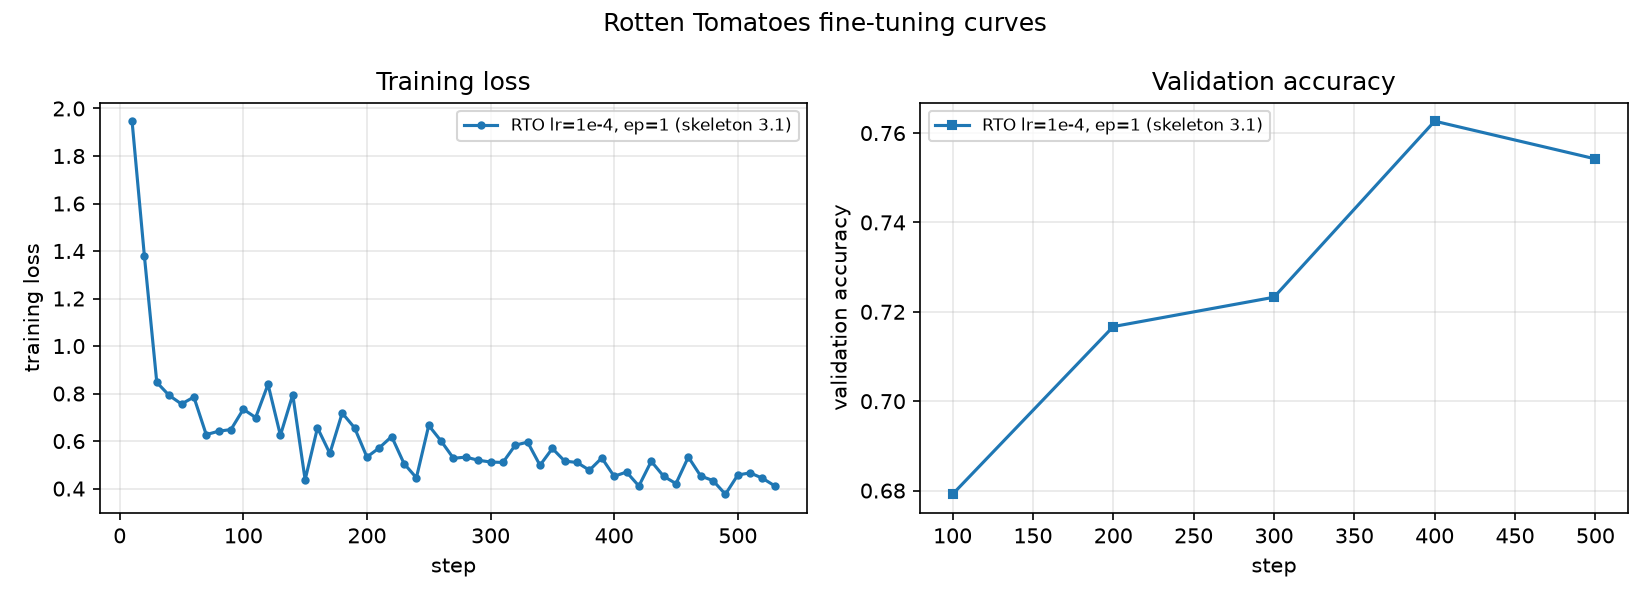

training_curves_sst5.png


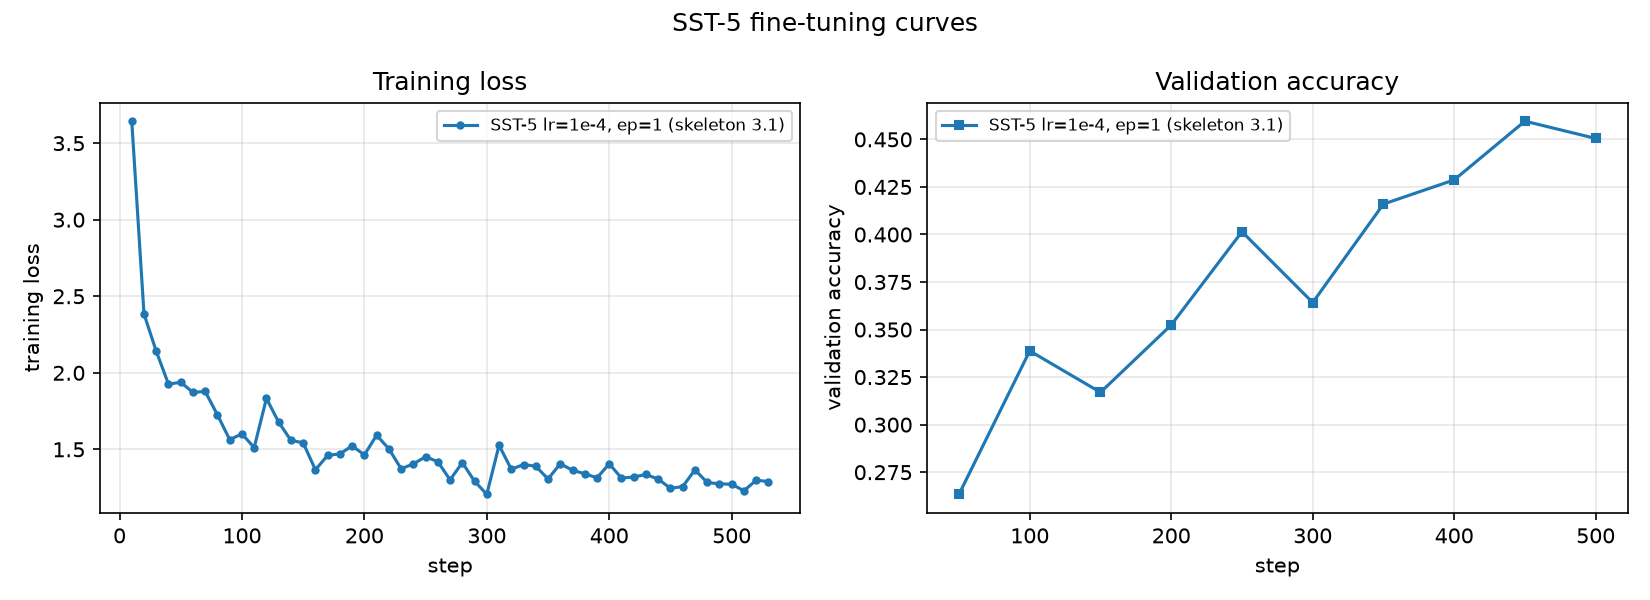

training_curves_added_rto.png


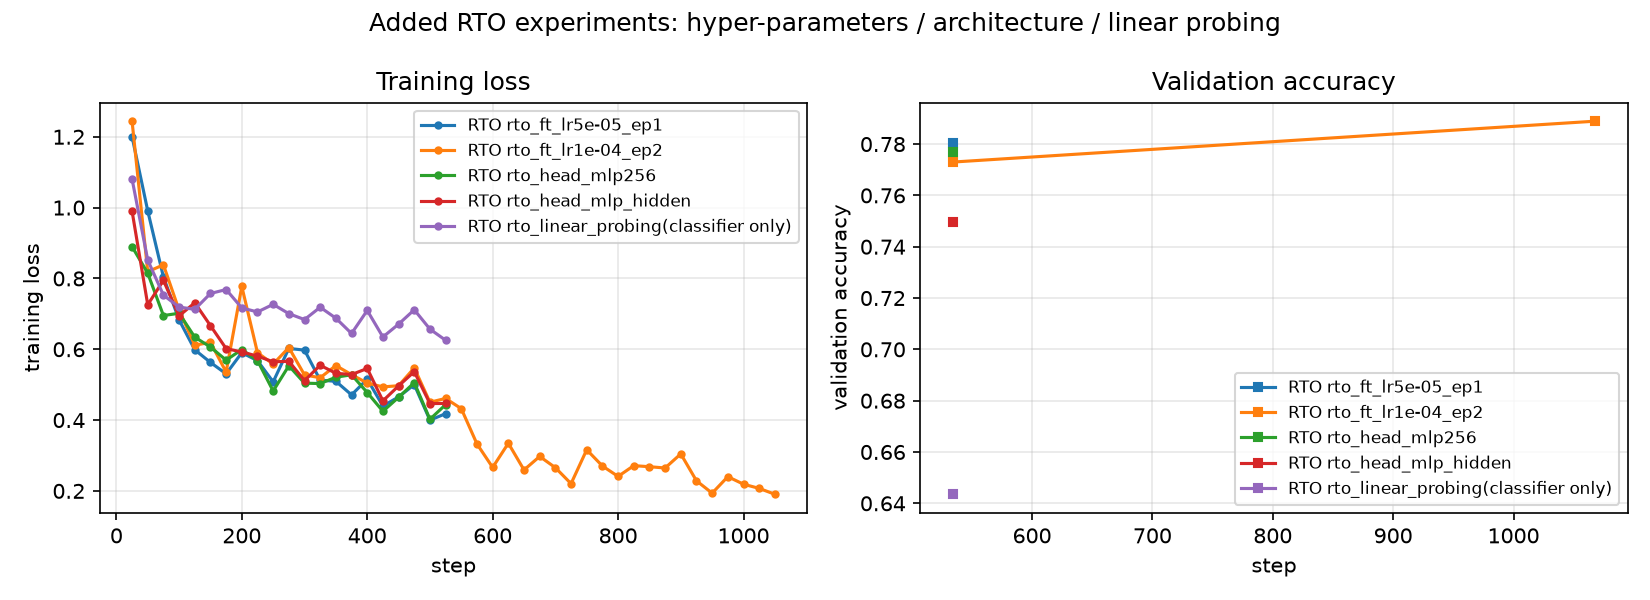

metrics_comparison_rto.png


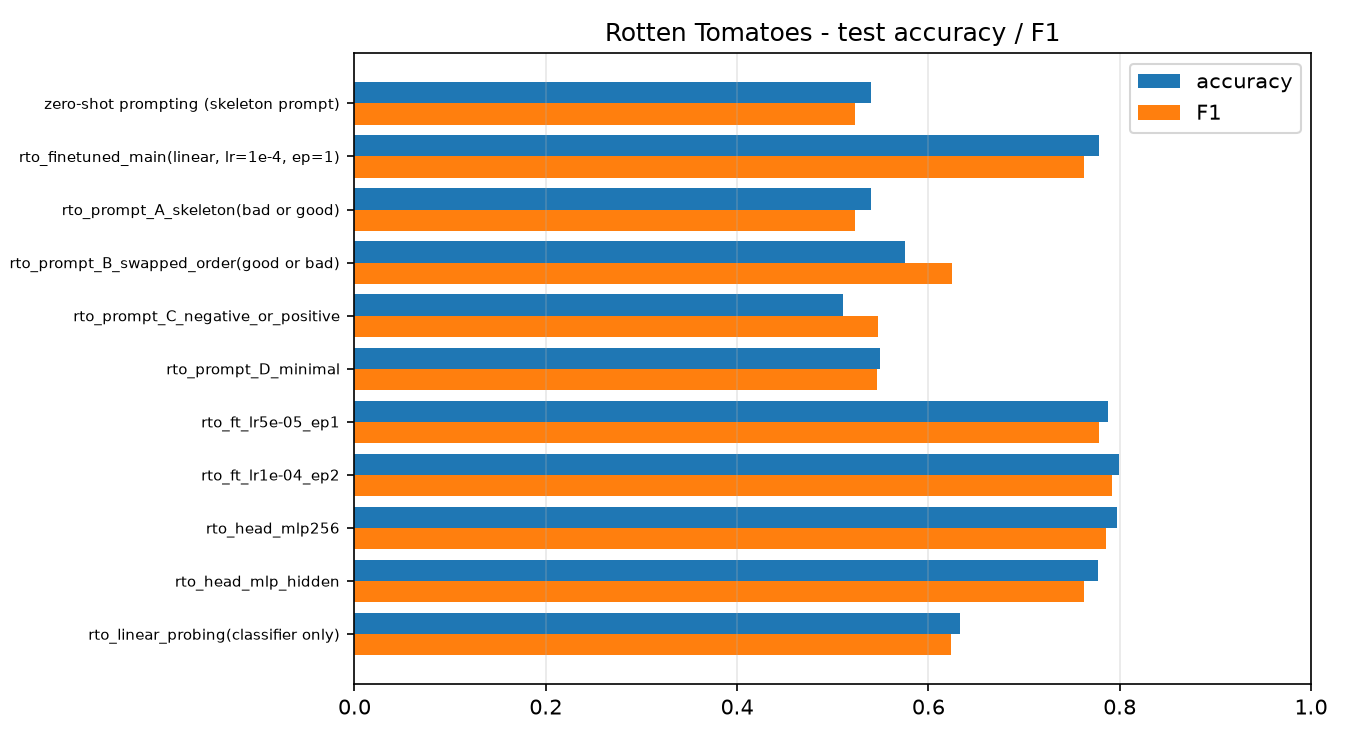

metrics_comparison_sst5.png


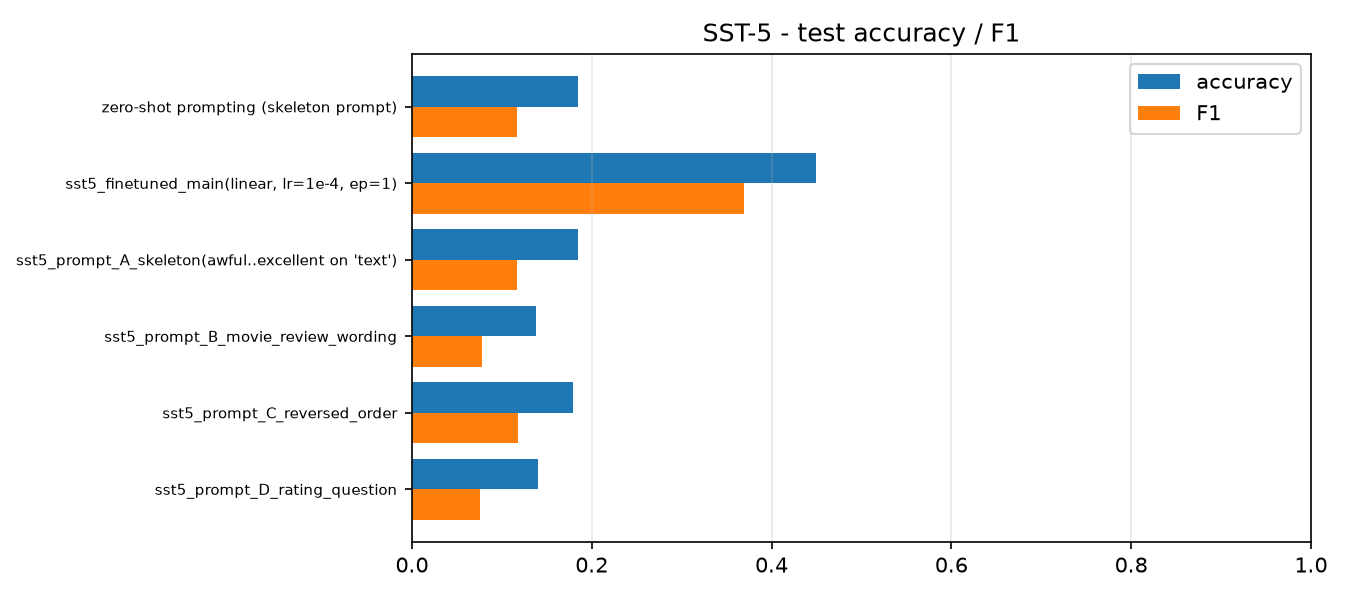

confusion_matrices_main.png


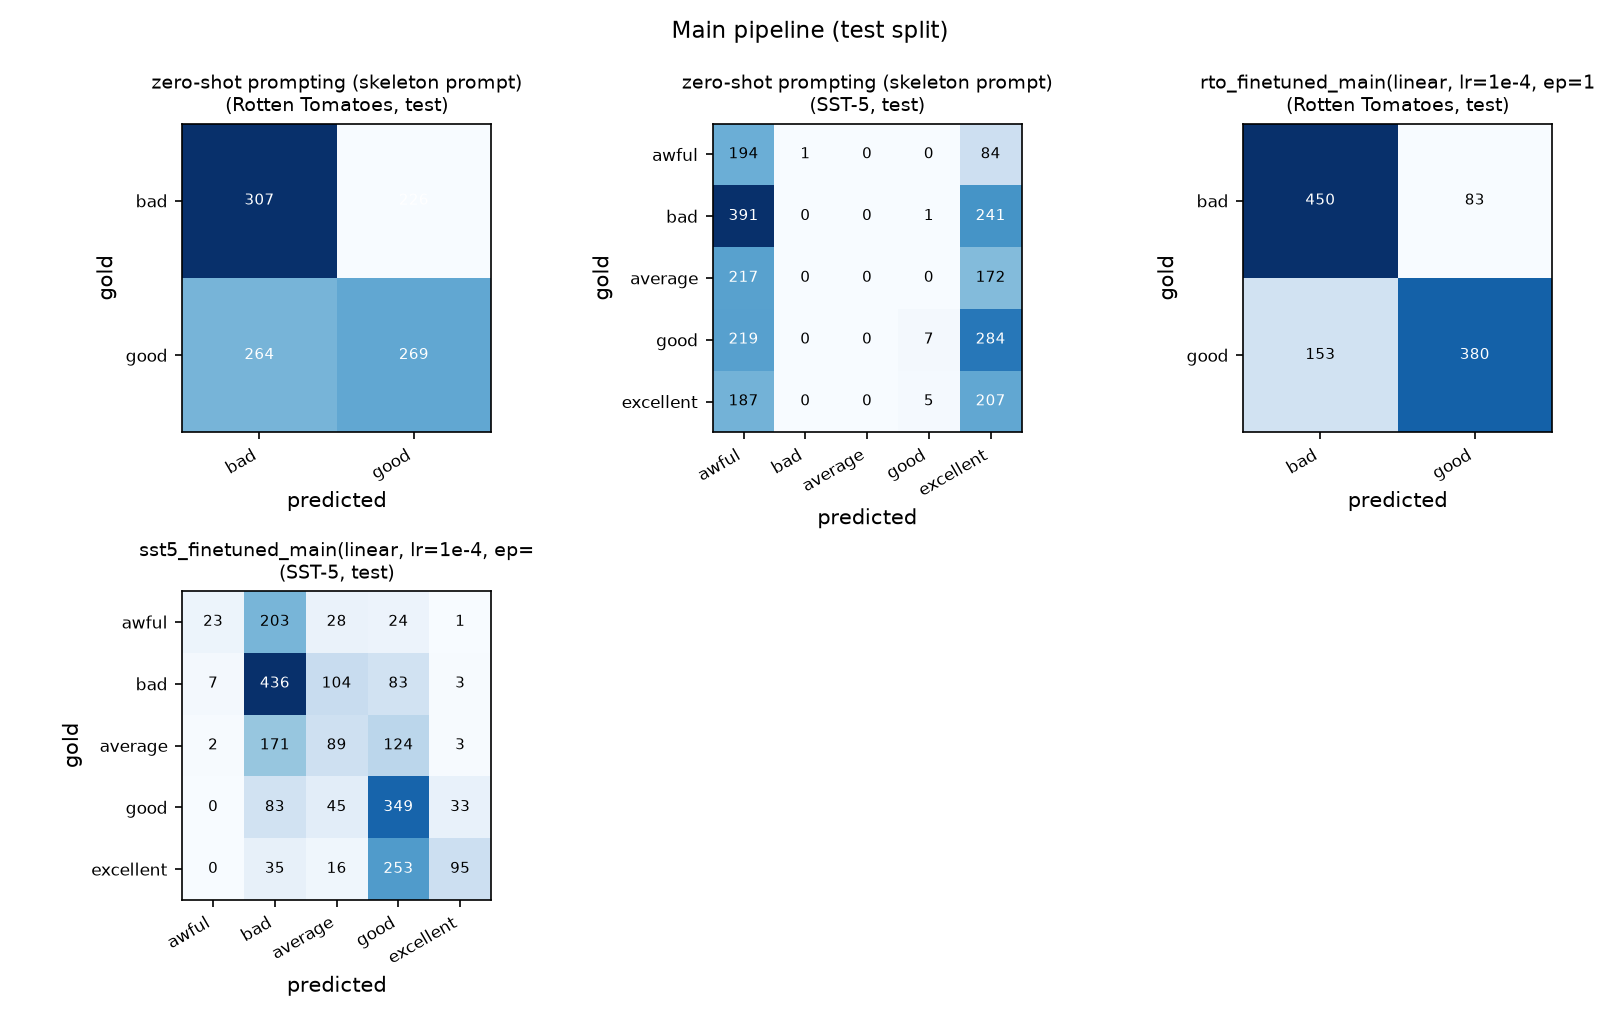

confusion_matrices_added.png


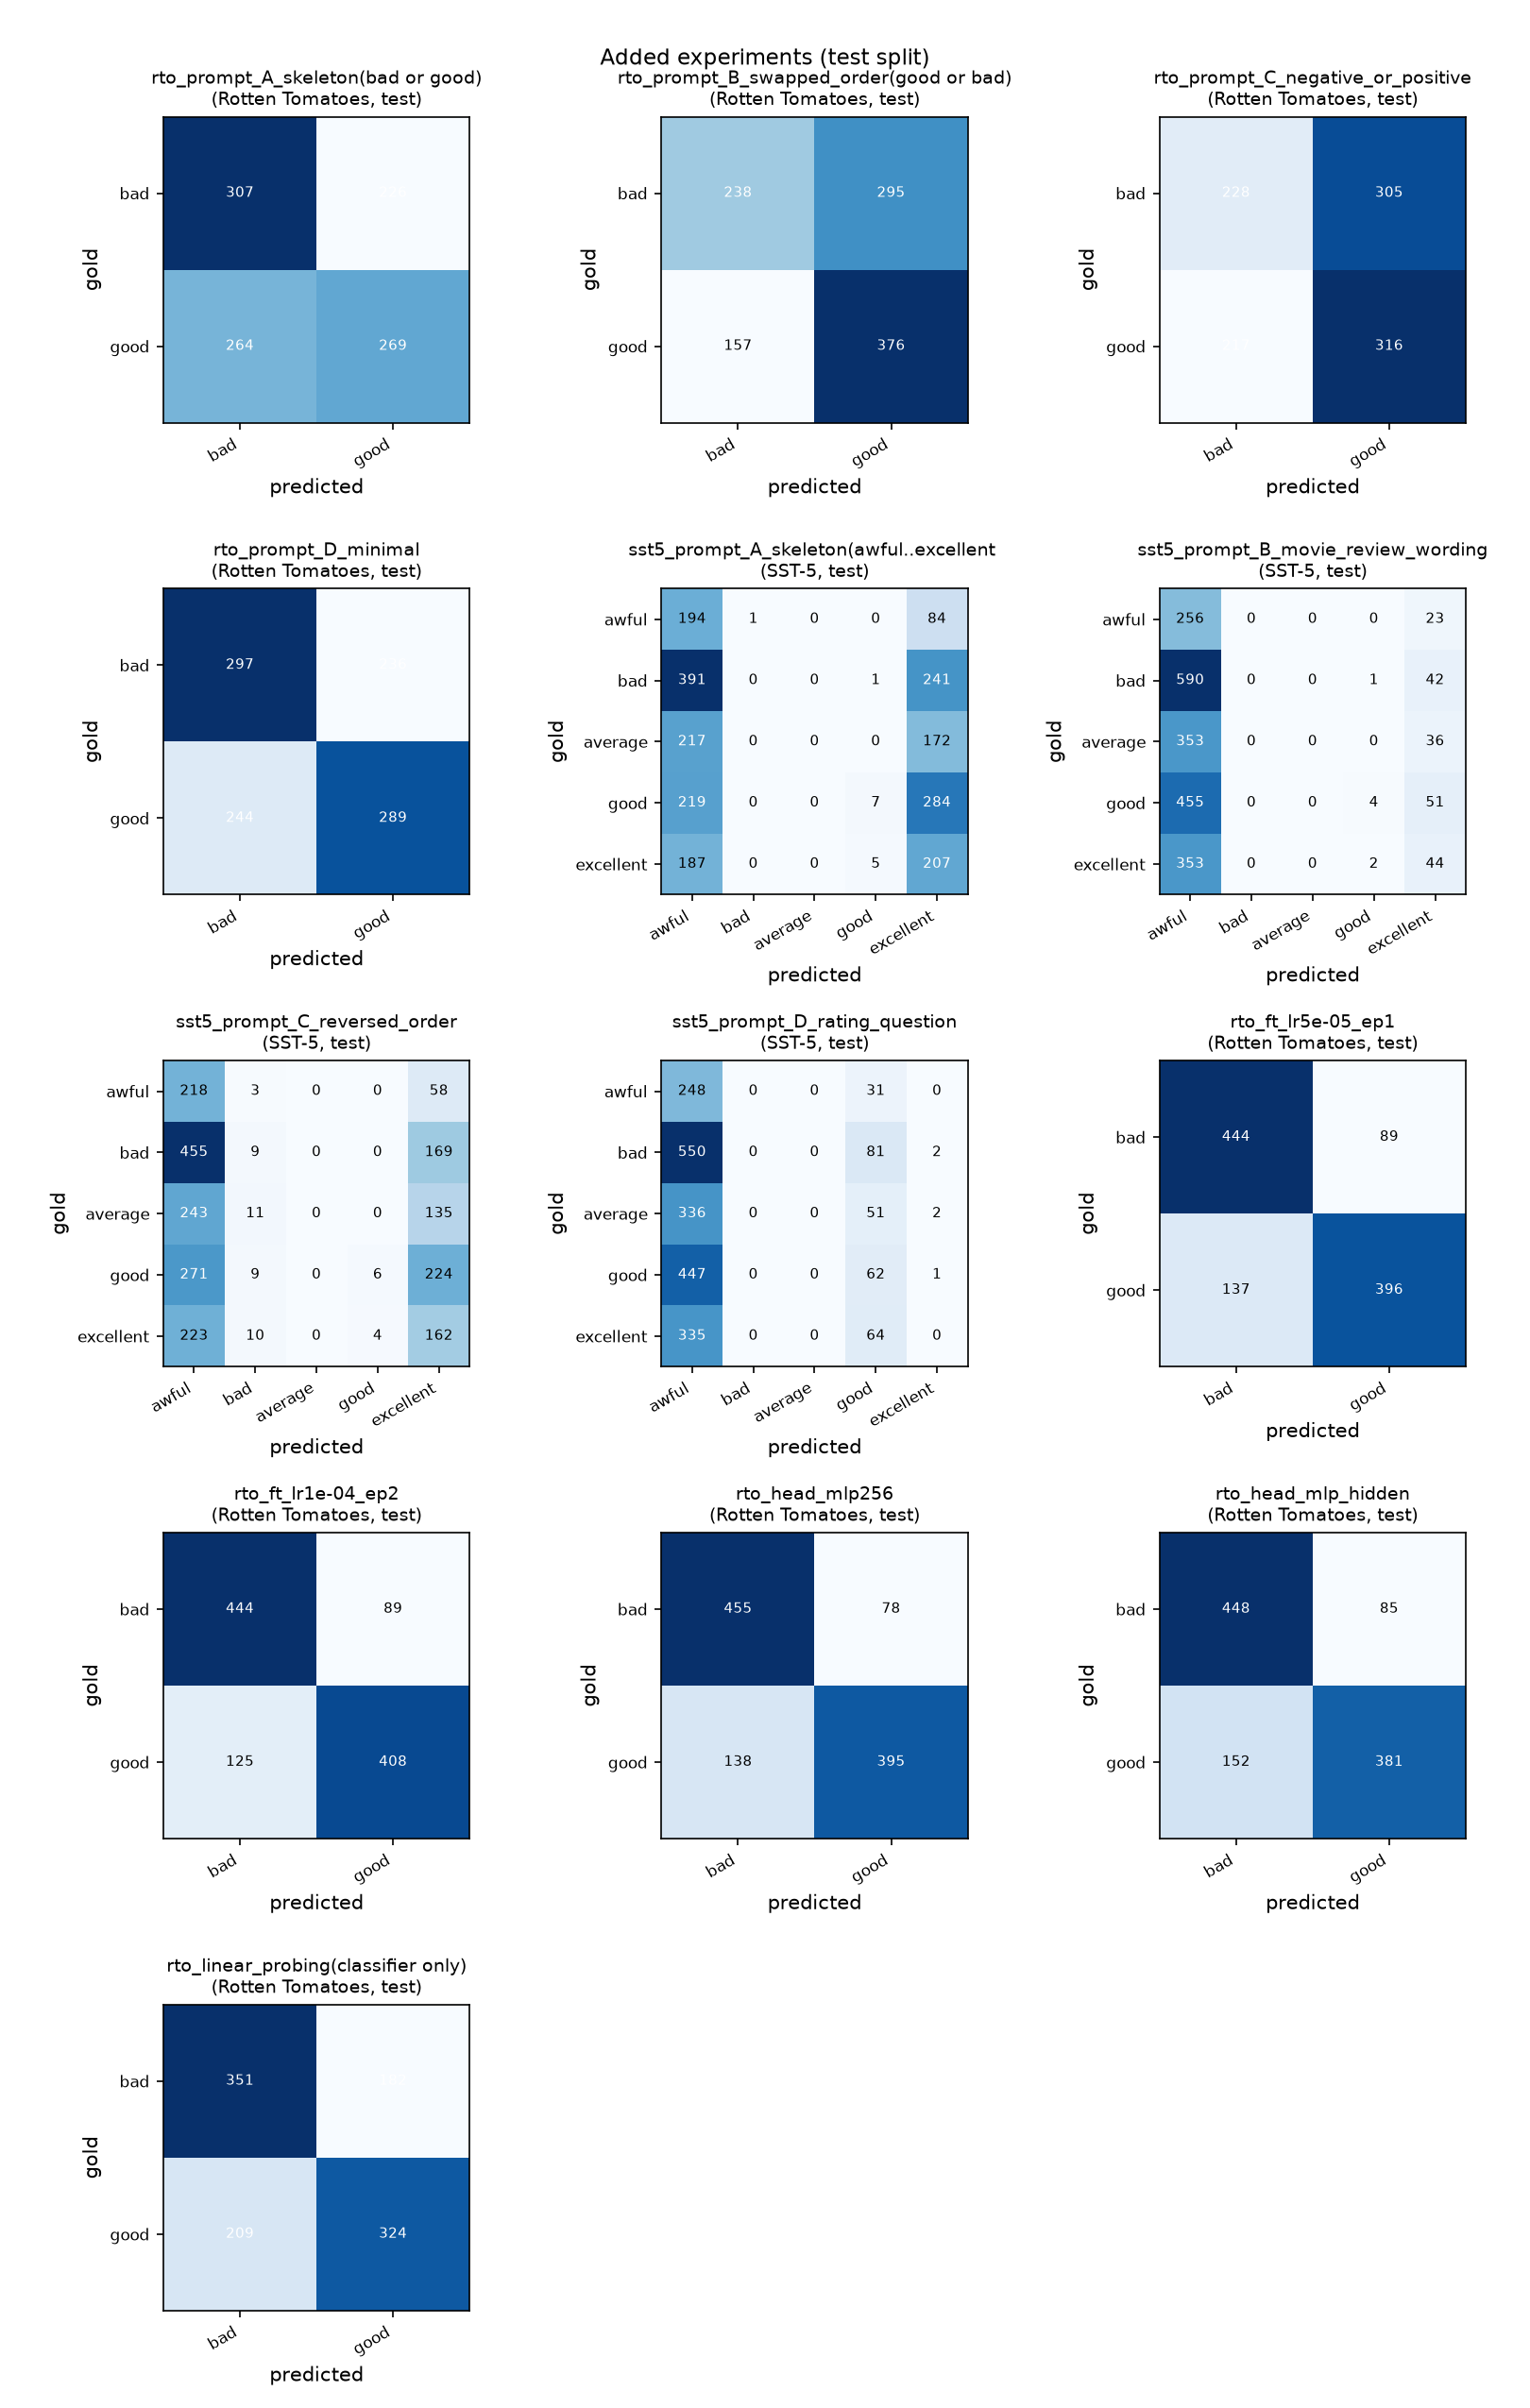

per_class_f1_rto.png


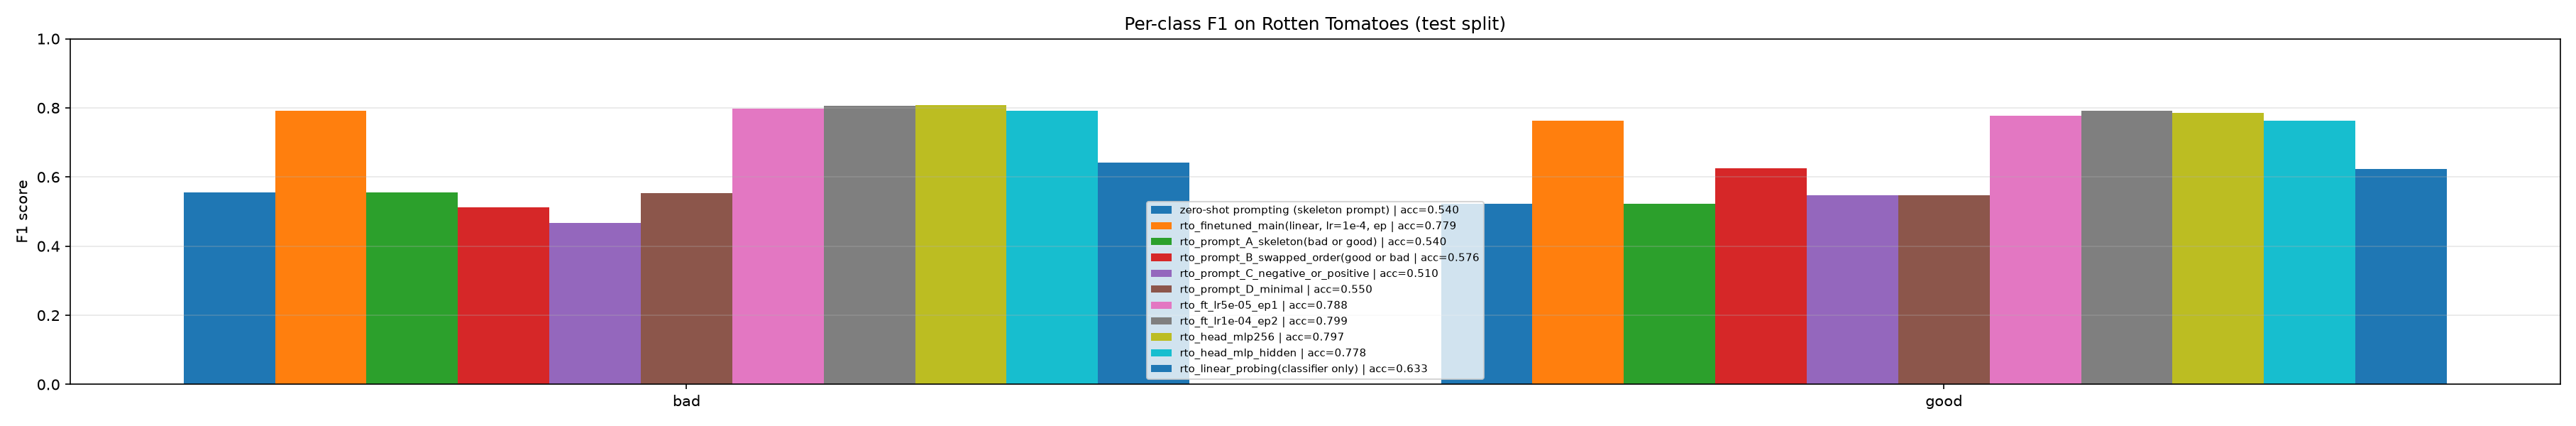

per_class_f1_sst5.png


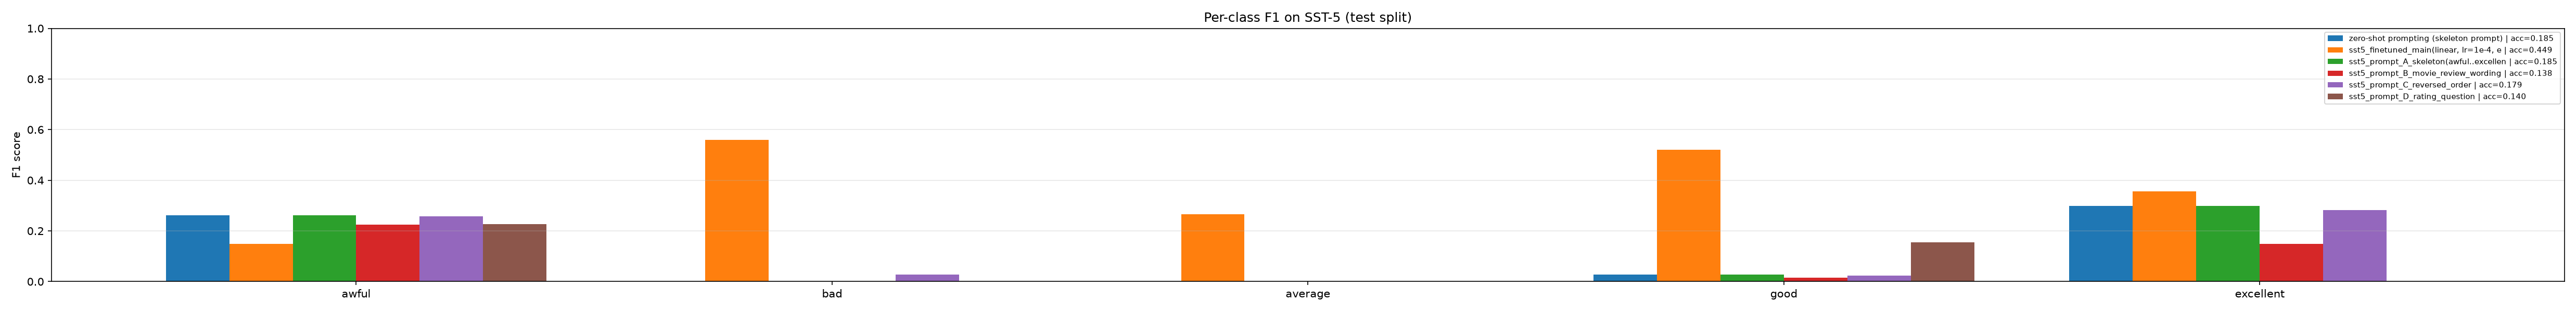

artifacts: ['added_experiment_records.json', 'all_experiment_metrics.csv', 'all_experiment_records.json', 'error_cases_rto_finetuned.csv', 'error_cases_rto_zeroshot.csv', 'error_cases_sst5_finetuned.csv', 'error_cases_sst5_zeroshot.csv', 'negation_share_rto_finetuned.csv', 'negation_share_rto_zeroshot.csv', 'negation_share_sst5_finetuned.csv', 'negation_share_sst5_zeroshot.csv', 'negation_share_summary.csv', 'task1_prompt_variants.csv', 'task1_prompt_variants.json']


In [20]:

# ===== Added: evidence package (4/4) - inline view of the key figures =====
# Every figure is also saved as a PNG under FIGURE_DIR / artifacts/ is CSV+JSON.
# The lines below display the most important ones inside the notebook so that the
# executed notebook is self-contained (the files themselves remain the deliverable).
try:
    from IPython.display import Image, display

    _KEY_FIGURES = [
        "training_curves_rto.png",
        "training_curves_sst5.png",
        "training_curves_added_rto.png",
        "metrics_comparison_rto.png",
        "metrics_comparison_sst5.png",
        "confusion_matrices_main.png",
        "confusion_matrices_added.png",
        "per_class_f1_rto.png",
        "per_class_f1_sst5.png",
    ]
    for _f in _KEY_FIGURES:
        _p = os.path.join(FIGURE_DIR, _f)
        if os.path.exists(_p):
            print(_f)
            display(Image(filename=_p))
    print("artifacts:", sorted(os.listdir(ARTIFACT_DIR)))
except Exception as _e:  # never break the run because of the inline preview
    print("inline preview skipped:", repr(_e))


In [21]:
# ===== Added: reproducible negation-share statistic used by the error analysis section =====
# The report quotes, for each of the four error sets, how many of the sampled errors contain
# an explicit negation marker.  The number is computed here so that the figure in the text is
# traceable to this cell and to the CSV files written into artifacts/.
#
# Definition (fixed here once, so the statistic is reproducible):
#   * the sample is the rows of artifacts/error_cases_<setting>.csv (the first 300 errors of
#     that configuration, the same files the case studies are taken from), so the denominator
#     is the number of rows of the file;
#   * a row counts as a hit when the review text, lower-cased, contains at least one marker
#     from NEGATION_LEXICON matched with word boundaries: (?<![a-z])marker(?![a-z]).
#     The texts are already space-tokenised, so "n't" is its own token;
#   * the share is a percentage of that denominator.

import csv
import os
import re

NEGATION_LEXICON = ["not", "n't", "never", "no", "nothing", "none", "nobody", "nowhere",
                    "neither", "nor", "cannot", "hardly", "scarcely", "barely", "rarely",
                    "seldom", "without"]

NEGATION_SETTINGS = [
    ("rto_zeroshot",   "Rotten Tomatoes", "error_cases_rto_zeroshot.csv"),
    ("rto_finetuned",  "Rotten Tomatoes", "error_cases_rto_finetuned.csv"),
    ("sst5_zeroshot",  "SST-5",           "error_cases_sst5_zeroshot.csv"),
    ("sst5_finetuned", "SST-5",           "error_cases_sst5_finetuned.csv"),
]


def _word_hit(text_lower, word):
    """True when *word* occurs in the lower-cased text as a stand-alone token."""
    return re.search(r"(?<![a-z])" + re.escape(word) + r"(?![a-z])", text_lower) is not None


def _negation_hit(text_lower):
    """True when the text contains at least one negation marker of the lexicon."""
    return any(_word_hit(text_lower, _w) for _w in NEGATION_LEXICON)


NEGATION_RESULTS = {}
_negation_summary_rows = []

for _setting, _dataset, _csv_name in NEGATION_SETTINGS:
    _path = os.path.join(ARTIFACT_DIR, _csv_name)
    _rows = list(csv.DictReader(open(_path, encoding="utf-8")))
    _total = len(_rows)
    _lowered = [_r["text"].lower() for _r in _rows]
    _per_word = {_w: sum(1 for _t in _lowered if _word_hit(_t, _w)) for _w in NEGATION_LEXICON}
    _count = sum(1 for _t in _lowered if _negation_hit(_t))
    _share = 100.0 * _count / _total if _total else 0.0

    with open(os.path.join(ARTIFACT_DIR, "negation_share_%s.csv" % _setting), "w",
              encoding="utf-8", newline="") as _f:
        _w = csv.writer(_f)
        _w.writerow(["word", "count"])
        for _marker in NEGATION_LEXICON:
            _w.writerow([_marker, _per_word[_marker]])

    NEGATION_RESULTS[_setting] = {"dataset": _dataset, "source": _csv_name,
                                  "total": _total, "negation_count": _count,
                                  "share": _share, "per_word": _per_word}
    _negation_summary_rows.append([_setting, _dataset, _total, _count, "%.1f" % _share])

with open(os.path.join(ARTIFACT_DIR, "negation_share_summary.csv"), "w",
          encoding="utf-8", newline="") as _f:
    _w = csv.writer(_f)
    _w.writerow(["setting", "dataset", "total", "negation_count", "share"])
    _w.writerows(_negation_summary_rows)

print("Negation-marker share among the first 300 sampled errors of each setting")
print("lexicon (%d markers): %s" % (len(NEGATION_LEXICON), ", ".join(NEGATION_LEXICON)))
print("match rule: lower-cased text, word boundary regex (?<![a-z])marker(?![a-z])")
print("")
print("%-16s %-16s %8s %10s %9s" % ("setting", "dataset", "errors", "negation", "share"))
for _setting, _dataset, _csv_name in NEGATION_SETTINGS:
    _r = NEGATION_RESULTS[_setting]
    print("%-16s %-16s %8d %10d %8.1f%%" % (_setting, _r["dataset"], _r["total"],
                                            _r["negation_count"], _r["share"]))
print("")
for _pair in (("rto", "Rotten Tomatoes"), ("sst5", "SST-5")):
    _zs = NEGATION_RESULTS[_pair[0] + "_zeroshot"]["share"]
    _ft = NEGATION_RESULTS[_pair[0] + "_finetuned"]["share"]
    print("%-16s zero-shot %.1f%% -> fine-tuned %.1f%% (%+.1f pt)"
          % (_pair[1], _zs, _ft, _ft - _zs))
print("")
print("written to %s:" % ARTIFACT_DIR)
for _f in ["negation_share_%s.csv" % _s for _s, _, _ in NEGATION_SETTINGS] + ["negation_share_summary.csv"]:
    print("  ", _f)


Negation-marker share among the first 300 sampled errors of each setting
lexicon (17 markers): not, n't, never, no, nothing, none, nobody, nowhere, neither, nor, cannot, hardly, scarcely, barely, rarely, seldom, without
match rule: lower-cased text, word boundary regex (?<![a-z])marker(?![a-z])

setting          dataset            errors   negation     share
rto_zeroshot     Rotten Tomatoes       300         51     17.0%
rto_finetuned    Rotten Tomatoes       300         62     20.7%
sst5_zeroshot    SST-5                 300         65     21.7%
sst5_finetuned   SST-5                 300         70     23.3%

Rotten Tomatoes  zero-shot 17.0% -> fine-tuned 20.7% (+3.7 pt)
SST-5            zero-shot 21.7% -> fine-tuned 23.3% (+1.7 pt)

written to C:\Users\07viv\Desktop\CISC7021_Ass2\artifacts:
   negation_share_rto_zeroshot.csv
   negation_share_rto_finetuned.csv
   negation_share_sst5_zeroshot.csv
   negation_share_sst5_finetuned.csv
   negation_share_summary.csv


In [22]:
# ===== Added: regression check for the zero-shot padding fix of cell 16 =====
# predict_prob() now reads the class scores of every sample at its own last *real* prompt
# token (the largest column whose attention mask is 1) instead of the fixed column
# logits[:, -1, :], which for a right-padded batch was a padding placeholder for every sample
# shorter than the longest one in the batch.
# The check below classifies the same 20 Rotten Tomatoes validation samples twice:
#   * batch_size=1  -> nothing is padded, so the fixed column was already the real last token;
#   * batch_size=64 -> the batch is padded to its longest prompt, the case that used to break.
# Both runs must predict the same labels; any mismatch means the scores are still read at a
# padded position.

PADDING_CHECK_N = 20
_pc_texts = rto_data["validation"]["text"][:PADDING_CHECK_N]
_pc_labels = rto_data["validation"]["label"][:PADDING_CHECK_N]

_pc_single = prompting_classification(model=model, tokenizer=tokenizer, dataset=_pc_texts,
                                      batch_size=1, label_mapping=RTO_DATA_LABEL_MAPPING,
                                      prompt=rto_prompt)
_pc_batched = prompting_classification(model=model, tokenizer=tokenizer, dataset=_pc_texts,
                                       batch_size=64, label_mapping=RTO_DATA_LABEL_MAPPING,
                                       prompt=rto_prompt)

_pc_acc_single = calculate_accuracy(y_true=_pc_labels, y_pred=_pc_single)
_pc_acc_batched = calculate_accuracy(y_true=_pc_labels, y_pred=_pc_batched)
_pc_mismatch = [(i, _pc_single[i], _pc_batched[i]) for i in range(PADDING_CHECK_N)
                if _pc_single[i] != _pc_batched[i]]

print(f"Zero-shot padding consistency check ({PADDING_CHECK_N} Rotten Tomatoes validation samples)")
print("  batch_size=1  predictions:", _pc_single)
print("  batch_size=64 predictions:", _pc_batched)
print(f"  accuracy: bs=1 {_pc_acc_single:.4f} | bs=64 {_pc_acc_batched:.4f}")
print(f"  identical: {not _pc_mismatch} (mismatches: {len(_pc_mismatch)})")
if _pc_mismatch:
    print("  MISMATCHES (index, bs=1, bs=64):", _pc_mismatch[:10])
assert not _pc_mismatch, "padding fix regression: batch_size=1 and batch_size=64 disagree"


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Zero-shot padding consistency check (20 Rotten Tomatoes validation samples)
  batch_size=1  predictions: [0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1]
  batch_size=64 predictions: [0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1]
  accuracy: bs=1 0.4500 | bs=64 0.4500
  identical: True (mismatches: 0)
